# Applied AI Midterm — SRGAN Super-Resolution for Dogs vs. Cats

**Author:** Shamik Desai

This notebook:

1. Trains **classifier A** (transfer learning, as in Assignment 1) on real 128×128 images.
2. Trains an **SRGAN** (≥150 adversarial epochs) that turns 32×32 images into 128×128 images.
3. Trains **classifier B** on SRGAN outputs and **classifier C** (control) on bicubic-upsampled images, using the identical recipe.
4. Compares A, B and C with Accuracy, F1 and AUC (plus confusion matrices, ROC curves and significance tests).

Every design choice is tagged in the code with its decision ID (D1–D6, K0–K9, G1–G7, L1–L7, T1–T7). The table below lists the options chosen.

**How to run on Colab:** Runtime → Change runtime type → GPU, then *Run all*. Every stage saves to Google Drive and **resumes or skips automatically** on re-run, so after a disconnect just *Run all* again. Set `QUICK_RUN = True` in the config cell for a ~15-minute end-to-end test on a small subset before the full run.

## Design decisions used

| ID | Decision | Choice |
|---|---|---|
| D1 | Non-square photo → 128×128 | B — resize shorter side to 128, center crop |
| D2 | Degradation 128→32 | A — bicubic with antialiasing |
| D3 | Data loading | A — decode once, cache uint8 HR on Drive, build LR on the fly |
| D4 | SR-pair augmentation | B — paired random horizontal flip |
| D5 | Value ranges | A — LR in [0,1], HR in [−1,1] |
| D6 | Tiny originals | C — keep, report the count |
| K0 | Framework | B — PyTorch |
| K1 | Backbone | C — ResNet50 (ImageNet) |
| K2 | Fine-tuning | A — frozen base, train head only |
| K3 | Head | A — GAP → Dense(256, ReLU) → Dropout(0.5) → Dense(1, sigmoid) |
| K4 | Input preprocessing | B — ImageNet mean/std |
| K5 | Optimizer | A — Adam 1e-4, binary cross-entropy |
| K6 | Epochs / early stopping | A — max 15, early stopping on val loss, patience 5, restore best |
| K7 | Batch size | B — 64 |
| K8 | Classifier augmentation | B — horizontal flip only |
| K9 | What B is tested on | C — both SR and real test images |
| G1 | Residual blocks | B — 16 |
| G2 | Normalization in blocks | B — none |
| G3 | Upsampling | A — conv → PixelShuffle(2), ICNR init |
| G4 | Activation | A — PReLU |
| G5 | Initialization | C — Kaiming × 0.1 in residual blocks |
| G6 | Long skip | B — global skip from first conv to end of trunk |
| G7 | Output | A — tanh |
| L1 | Discriminator | A — SRGAN paper: 8 conv blocks → dense 1024 → 1 logit |
| L2 | D normalization | B — spectral norm |
| L3 | Adversarial loss | A — vanilla (non-saturating) BCE |
| L4 | D labels | B — one-sided smoothing, real = 0.9 |
| L5 | Pixel loss | B — L1 |
| L6 | Perceptual loss | B — VGG19 features before the conv5_4 activation |
| L7 | Loss weights pix / perc / adv | C — 1 / 6e-3 / 1e-3 |
| T1 | Warm start | B — 20 pixel-only epochs, then 150 GAN epochs |
| T2 | Optimizers | A — Adam 1e-4, betas (0.9, 0.999) for G and D |
| T3 | LR schedule | B — ×0.1 at GAN epoch 100 |
| T4 | SRGAN batch size | B — 32 |
| T5 | Precision | B — mixed precision (autocast + GradScaler) |
| T6 | Checkpoints | B — every 5 epochs (full state as latest/best, G-only snapshots) |
| T7 | Checkpoint for B's data | C — best classifier-A accuracy on SR validation images |

## 0. Setup

In [ ]:
import os, io, json, math, time, random, zipfile, glob, shutil, copy
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch                       # K0 B: PyTorch for classifiers and SRGAN
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.models import resnet50, ResNet50_Weights, vgg19, VGG19_Weights
from torch.nn.utils.parametrizations import spectral_norm

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, ConfusionMatrixDisplay)
from scipy.stats import binomtest

print('PyTorch', torch.__version__, '| torchvision', torchvision.__version__)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('No GPU detected. Runtime -> Change runtime type -> GPU (the full run needs one).')

PyTorch 2.11.0+cu130 | torchvision 0.26.0+cu130
GPU: Tesla T4


In [ ]:
# ------------------------------- CONFIG ---------------------------------------
QUICK_RUN = False      # True = small subset + few epochs, to test the whole pipeline first
PRETRAINED = True      # keep True: ImageNet weights for ResNet50 (K1) and VGG19 (L6)

# Paths (fixed protocol)
ARCHIVE_PATH = '/content/drive/My Drive/6119_datasets/archive.zip'
EXTRACT_PATH = '/content/dataset'
WORK_DIR     = '/content/drive/My Drive/srgan_midterm'
if QUICK_RUN:
    WORK_DIR += '_quick'           # keeps test outputs away from the real run

SEED = 6165                        # fixed protocol
CLASS_NAMES = ['cats', 'dogs']     # cats = 0, dogs = 1 (Assignment 1 class_indices)

# Data (fixed protocol + D decisions)
HR_SIZE, LR_SIZE, SCALE = 128, 32, 4
TEST_FRACTION = 0.30               # 70/30 split
VAL_FRACTION_OF_TRAIN = 0.10       # validation held out from train for all selection

# Classifier recipe (K decisions) -- identical for A, B and C
CLS_BATCH = 64                     # K7 B
CLS_LR = 1e-4                      # K5 A (ResNet50 value from Assignment 1)
CLS_MAX_EPOCHS = 15                # K6 A
CLS_PATIENCE = 5                   # K6 A
CLASSIFIER_SEEDS = [SEED]          # add 6166, 6167 for mean +/- std if time allows

# SRGAN (G, L and T decisions)
N_RES_BLOCKS = 16                  # G1 B
G_CHANNELS = 64
PRETRAIN_EPOCHS = 20               # T1 B
GAN_EPOCHS = 150                   # T1 B (exam requires >= 150)
LR_DROP_EPOCH = 100                # T3 B
GAN_LR = 1e-4                      # T2 A
ADAM_BETAS = (0.9, 0.999)          # T2 A
SR_BATCH = 32                      # T4 B
USE_AMP = DEVICE.type == 'cuda'    # T5 B
SAVE_EVERY = 5                     # T6 B
W_PIX, W_PERC, W_ADV = 1.0, 6e-3, 1e-3   # L7 C
REAL_LABEL = 0.9                   # L4 B
TIE_TOLERANCE = 1.0                # T7 C: accuracy points treated as a tie

if QUICK_RUN:
    QUICK_N_IMAGES = 1200
    PRETRAIN_EPOCHS, GAN_EPOCHS, LR_DROP_EPOCH, SAVE_EVERY = 2, 4, 3, 1
    CLS_MAX_EPOCHS = 3
    print('QUICK_RUN: outputs go to', WORK_DIR, '- NOT a valid submission run.')

# Mount Google Drive (Colab); outside Colab, paths are used as-is
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running on Colab: skipping drive.mount')

SUBDIRS = ['cache', 'classifiers', 'srgan', 'srgan/snapshots', 'srgan/progress', 'figures']
for d in SUBDIRS:
    os.makedirs(os.path.join(WORK_DIR, d), exist_ok=True)
P = lambda *parts: os.path.join(WORK_DIR, *parts)
RESULTS = {}   # filled as the notebook runs; feeds the workbook at the end
print('Work dir:', WORK_DIR)

Mounted at /content/drive
Work dir: /content/drive/My Drive/srgan_midterm


In [ ]:
def set_seed(seed=SEED):
    """Fixed protocol: call before every model construction and run."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.benchmark = True   # speed; GPU results are close but not bit-identical run to run

def atomic_save(obj, path):
    """Save to a temp file, then rename, so a disconnect never corrupts the target."""
    tmp = path + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)

def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if p.requires_grad or not trainable_only)

set_seed()

## 1. Data: extract, pool, cache (D1, D3, D6) and split 70/30

The archive comes pre-split 80/10/10 (19,943 / 2,492 / 2,495). The midterm requires 70/30, so all 24,930 images are pooled and re-split.

* **D1 B** — resize the shorter side to 128, then center crop to 128×128 (keeps proportions).
* **D3 A** — decode every JPEG once and cache the 128×128 uint8 images on Drive; low-resolution images are built on the fly.
* **D6 C** — originals with a shorter side under 128 px are kept and counted.

In [ ]:
# Unzip archive.zip from Drive into local Colab storage (same as Assignment 1)
if not os.path.exists(EXTRACT_PATH):
    os.makedirs(EXTRACT_PATH)
    with zipfile.ZipFile(ARCHIVE_PATH, 'r') as zf:
        zf.extractall(EXTRACT_PATH)
    print('Extracted to', EXTRACT_PATH)
else:
    print(EXTRACT_PATH, 'already exists, skipping extraction')

DATASET_ROOT = os.path.join(EXTRACT_PATH, 'dogs-vs-cats-classification')
records = []
for split in ['train', 'validation', 'test']:
    for label, cls in enumerate(CLASS_NAMES):
        files = sorted(glob.glob(os.path.join(DATASET_ROOT, split, cls, '*')))
        records += [{'path': f, 'orig_split': split, 'label': label} for f in files]
meta = pd.DataFrame(records)
print(meta.groupby(['orig_split', 'label']).size().unstack())
print('Total images found:', len(meta))

Extracted to /content/dataset
label          0     1
orig_split            
test        1248  1247
train       9977  9966
validation  1247  1245
Total images found: 24930


In [ ]:
CACHE_HR = P('cache', 'hr_uint8.npy')
CACHE_META = P('cache', 'meta.csv')

def load_center_crop(path, size=HR_SIZE):
    """D1 B: resize shorter side to `size` (PIL bicubic, antialiased), then center crop."""
    try:
        with Image.open(path) as im:
            im = im.convert('RGB')
            w, h = im.size
            s = size / min(w, h)
            nw, nh = max(size, round(w * s)), max(size, round(h * s))
            im = im.resize((nw, nh), Image.BICUBIC)
            left, top = (nw - size) // 2, (nh - size) // 2
            im = im.crop((left, top, left + size, top + size))
            return np.asarray(im, dtype=np.uint8), w, h, True
    except Exception as e:
        print('Unreadable image skipped:', path, e)
        return None, 0, 0, False

if os.path.exists(CACHE_HR) and os.path.exists(CACHE_META):
    print('Loading cached HR images from Drive (D3 A)...')
    HR = np.load(CACHE_HR)
    meta = pd.read_csv(CACHE_META)
else:
    if QUICK_RUN:
        meta = meta.groupby('label').sample(n=QUICK_N_IMAGES // 2, random_state=SEED).reset_index(drop=True)
    t0 = time.time()
    with ThreadPoolExecutor(max_workers=8) as ex:
        out = list(ex.map(load_center_crop, meta['path']))
    ok = np.array([o[3] for o in out])
    meta['orig_w'] = [o[1] for o in out]
    meta['orig_h'] = [o[2] for o in out]
    meta = meta[ok].reset_index(drop=True)
    HR = np.stack([o[0] for o in out if o[3]])
    np.save(CACHE_HR, HR)
    meta.to_csv(CACHE_META, index=False)
    print(f'Decoded and cached {len(HR)} images in {time.time() - t0:.0f}s')

LABELS = meta['label'].to_numpy().astype(np.int64)
print('HR cache:', HR.shape, HR.dtype, f'{HR.nbytes / 1e9:.2f} GB')

Loading cached HR images from Drive (D3 A)...
HR cache: (24930, 128, 128, 3) uint8 1.23 GB


Originals with shorter side < 128px: 513 of 24930 (2.06%) - kept (D6 C)


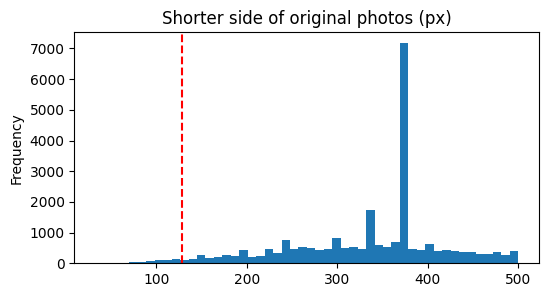

In [ ]:
# D6 C: keep tiny originals, report how many there are
meta['short_side'] = meta[['orig_w', 'orig_h']].min(axis=1)
n_small = int((meta['short_side'] < HR_SIZE).sum())
RESULTS['D6_small_count'] = n_small
print(f'Originals with shorter side < {HR_SIZE}px: {n_small} of {len(meta)} '
      f'({100 * n_small / len(meta):.2f}%) - kept (D6 C)')
meta['short_side'].plot.hist(bins=50, figsize=(6, 3), title='Shorter side of original photos (px)')
plt.axvline(HR_SIZE, color='r', ls='--'); plt.show()

In [ ]:
# Fixed protocol: stratified 70/30, then 10% of train held out as validation
idx_all = np.arange(len(LABELS))
idx_trainfull, idx_test = train_test_split(idx_all, test_size=TEST_FRACTION,
                                           stratify=LABELS, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainfull, test_size=VAL_FRACTION_OF_TRAIN,
                                      stratify=LABELS[idx_trainfull], random_state=SEED)
idx_train, idx_val, idx_test = np.sort(idx_train), np.sort(idx_val), np.sort(idx_test)
SPLITS = {'train': idx_train, 'val': idx_val, 'test': idx_test}
with open(P('cache', 'split_indices.json'), 'w') as f:
    json.dump({k: v.tolist() for k, v in SPLITS.items()}, f)

summary = pd.DataFrame({k: [len(v), int((LABELS[v] == 0).sum()), int((LABELS[v] == 1).sum())]
                        for k, v in SPLITS.items()}, index=['images', 'cats', 'dogs']).T
summary['share of total'] = (summary['images'] / len(LABELS)).round(3)
RESULTS['split_counts'] = summary['images'].to_dict()
display(summary)

,images,cats,dogs,share of total
train,15705,7857,7848,0.63
val,1746,873,873,0.07
test,7479,3742,3737,0.30


## 2. Scaling, normalization and transformations (D2, D4, D5, K4, K8)

* **D2 A** — LR = bicubic downsampling **with antialiasing**, 128→32. The same function makes the SRGAN inputs, the test LR images and control C's inputs.
* **D4 B** — SR training pairs get a paired random horizontal flip. LR is computed *from* the flipped HR, so the pair always matches.
* **D5 A** — generator input LR in [0, 1]; HR targets and generator output in [−1, 1].
* **K4 B / K8 B** — classifier inputs are ImageNet-normalized; classifier training uses random horizontal flips only.

In [ ]:
IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406], device=DEVICE).view(1, 3, 1, 1)
IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225], device=DEVICE).view(1, 3, 1, 1)

def u8_to_01(x_u8):
    """numpy uint8 (B,H,W,3) -> float tensor (B,3,H,W) in [0,1] on DEVICE."""
    return torch.from_numpy(np.ascontiguousarray(x_u8)).to(DEVICE).permute(0, 3, 1, 2).contiguous().float().div_(255.0)

def t01_to_u8(x01):
    """float tensor (B,3,H,W) in [0,1] -> numpy uint8 (B,H,W,3)."""
    return (x01.clamp(0, 1) * 255.0).round().byte().permute(0, 2, 3, 1).cpu().numpy()

def hr_to_lr(hr01):
    """D2 A: bicubic downsampling with antialiasing, 128 -> 32."""
    return F.interpolate(hr01, size=(LR_SIZE, LR_SIZE), mode='bicubic',
                         align_corners=False, antialias=True).clamp(0, 1)

def bicubic_up(lr01):
    """Control C: plain bicubic upsampling 32 -> 128."""
    return F.interpolate(lr01, size=(HR_SIZE, HR_SIZE), mode='bicubic',
                         align_corners=False).clamp(0, 1)

def random_hflip(x):
    """D4 B / K8 B: flip each image left-right with probability 0.5 (exact pixel permutation)."""
    mask = torch.rand(x.shape[0], device=x.device) < 0.5
    x = x.clone()
    x[mask] = x[mask].flip(-1)
    return x

to_m11 = lambda x01: x01 * 2 - 1          # D5 A: [0,1] -> [-1,1]
to_01 = lambda xm11: (xm11 + 1) / 2       # [-1,1] -> [0,1]
imagenet_norm = lambda x01: (x01 - IMAGENET_MEAN) / IMAGENET_STD   # K4 B

def batches(indices, batch_size, shuffle, epoch_seed=None):
    """Yield index batches; shuffling is seeded per epoch so resumed runs see the same order."""
    idx = np.asarray(indices)
    if shuffle:
        rng = np.random.default_rng(epoch_seed)
        idx = idx[rng.permutation(len(idx))]
    for i in range(0, len(idx), batch_size):
        yield np.sort(idx[i:i + batch_size])

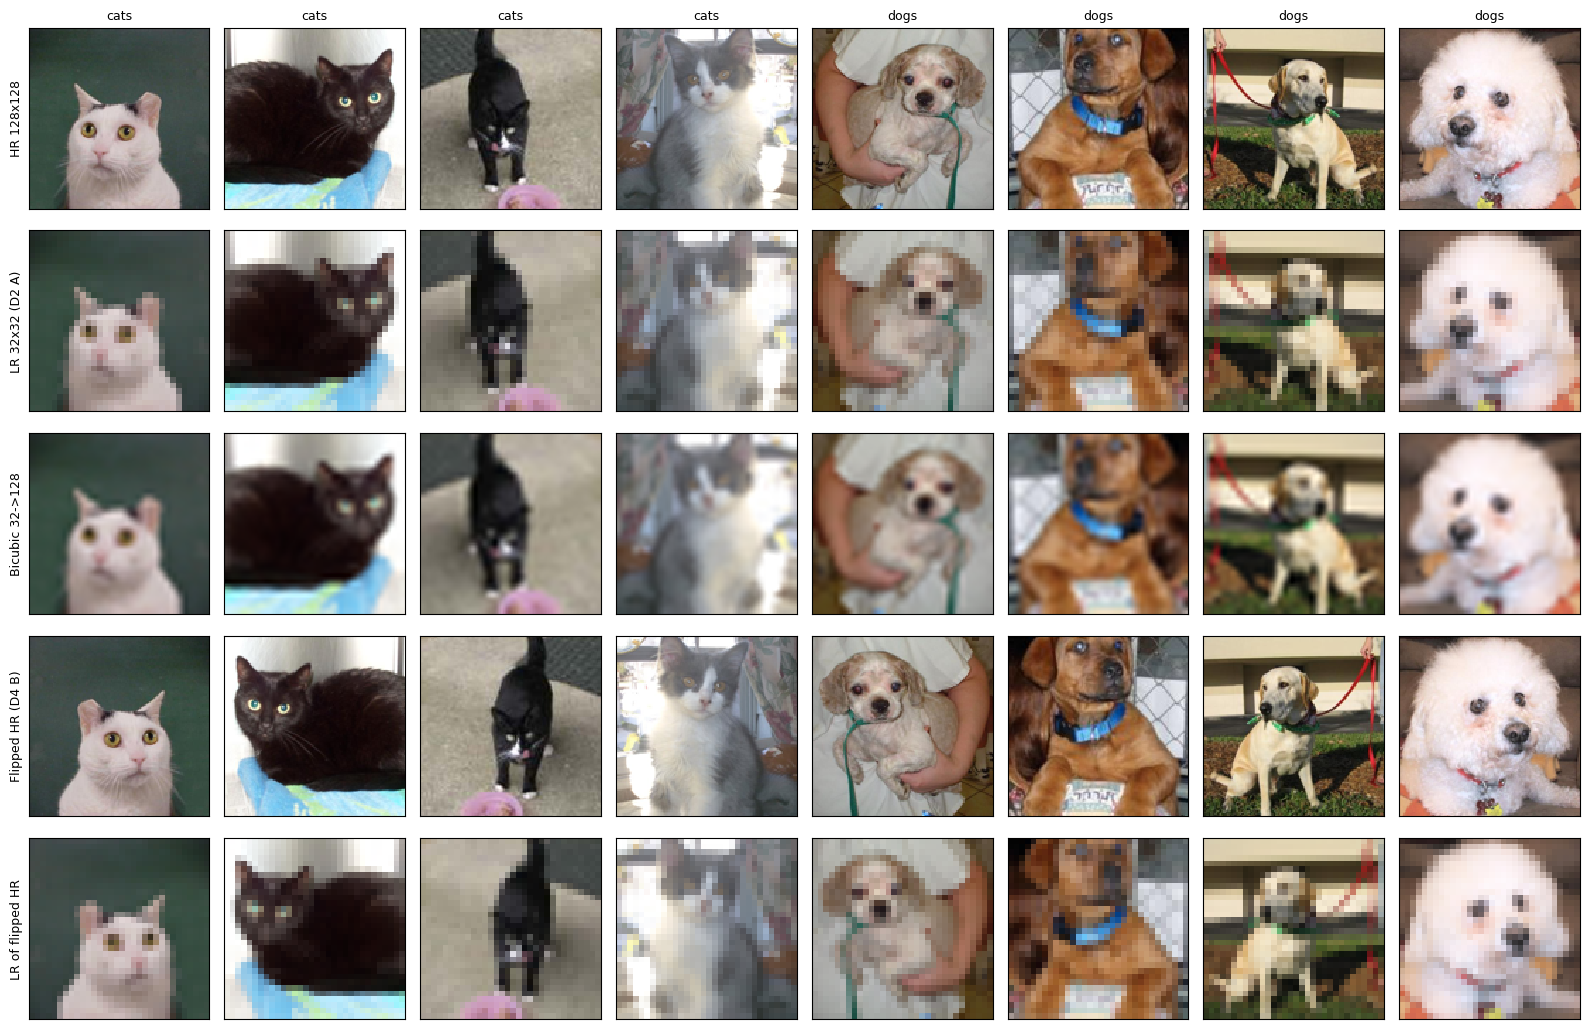

Shapes  HR (8, 3, 128, 128) | LR (8, 3, 32, 32) | bicubic (8, 3, 128, 128)


In [ ]:
# Show scaled images: HR 128x128, LR 32x32, bicubic 32->128, and a paired flip
show_idx = np.concatenate([idx_val[LABELS[idx_val] == 0][:4], idx_val[LABELS[idx_val] == 1][:4]])
FIXED_GRID_IDX = show_idx            # also used for the SRGAN progress grid
hr01 = u8_to_01(HR[show_idx])
lr01 = hr_to_lr(hr01)
bic01 = bicubic_up(lr01)
flip_hr = hr01.flip(-1); flip_lr = hr_to_lr(flip_hr)

def show_rows(rows, row_titles, col_titles=None, path=None, figsize=None):
    n_r, n_c = len(rows), rows[0].shape[0]
    fig, axes = plt.subplots(n_r, n_c, figsize=figsize or (2 * n_c, 2.1 * n_r))
    for r, (imgs, title) in enumerate(zip(rows, row_titles)):
        for c in range(n_c):
            ax = axes[r, c]
            ax.imshow(imgs[c].detach().float().clamp(0, 1).permute(1, 2, 0).cpu().numpy(),
                      interpolation='nearest')
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0: ax.set_ylabel(title, fontsize=9)
            if r == 0 and col_titles is not None: ax.set_title(col_titles[c], fontsize=9)
    plt.tight_layout()
    if path: plt.savefig(path, dpi=110)
    plt.show()

cols = [CLASS_NAMES[l] for l in LABELS[show_idx]]
show_rows([hr01, lr01, bic01, flip_hr, flip_lr],
          ['HR 128x128', 'LR 32x32 (D2 A)', 'Bicubic 32->128', 'Flipped HR (D4 B)', 'LR of flipped HR'],
          cols, path=P('figures', 'scaled_examples.png'))
print('Shapes  HR', tuple(hr01.shape), '| LR', tuple(lr01.shape), '| bicubic', tuple(bic01.shape))

Before normalization, per-channel mean/std: [0.532 0.497 0.461] [0.265 0.261 0.271]
After ImageNet normalization, per-channel mean/std: [0.205 0.182 0.244] [1.158 1.166 1.203]
SRGAN ranges (D5 A): LR [0.0, 1.0] | HR target [-1.0, 1.0]


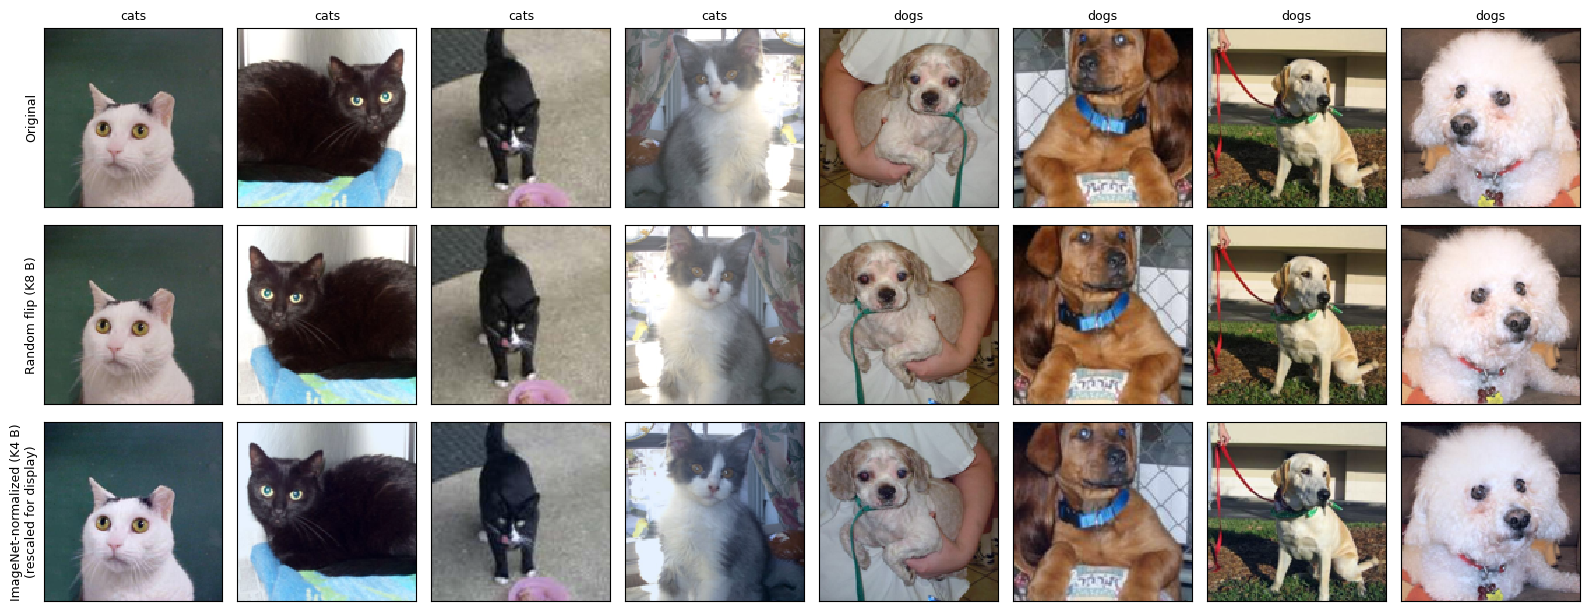

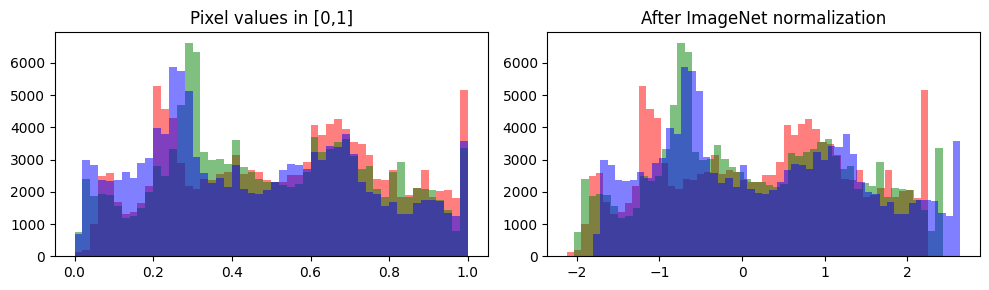

In [ ]:
# Normalization and transformations used by the classifiers (K4 B, K8 B) and the SRGAN (D5 A)
aug = random_hflip(hr01)
norm = imagenet_norm(aug)
print('Before normalization, per-channel mean/std:',
      hr01.mean((0, 2, 3)).cpu().numpy().round(3), hr01.std((0, 2, 3)).cpu().numpy().round(3))
print('After ImageNet normalization, per-channel mean/std:',
      norm.mean((0, 2, 3)).cpu().numpy().round(3), norm.std((0, 2, 3)).cpu().numpy().round(3))
print('SRGAN ranges (D5 A): LR', [round(lr01.min().item(), 2), round(lr01.max().item(), 2)],
      '| HR target', [round(to_m11(hr01).min().item(), 2), round(to_m11(hr01).max().item(), 2)])

# Display normalized images by min-max rescaling each image, only for viewing
vis = (norm - norm.amin((1, 2, 3), keepdim=True)) / (norm.amax((1, 2, 3), keepdim=True) - norm.amin((1, 2, 3), keepdim=True))
show_rows([hr01, aug, vis], ['Original', 'Random flip (K8 B)', 'ImageNet-normalized (K4 B)\n(rescaled for display)'],
          cols, path=P('figures', 'transformed_examples.png'))

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ch, col in enumerate(['r', 'g', 'b']):
    axes[0].hist(hr01[:, ch].flatten().cpu().numpy(), bins=50, alpha=0.5, color=col)
    axes[1].hist(norm[:, ch].flatten().cpu().numpy(), bins=50, alpha=0.5, color=col)
axes[0].set_title('Pixel values in [0,1]'); axes[1].set_title('After ImageNet normalization')
plt.tight_layout(); plt.show()

## 3. Classifier recipe and model A (K0–K9)

One recipe, used unchanged for A, B and C (fixed protocol). It reproduces Assignment 1's setup in PyTorch (K0 B) with the two Assignment 1 bugs fixed: every epoch uses the full training set, and inputs get proper ImageNet preprocessing (K4 B).

* **K1 C / K2 A** — ImageNet ResNet50, frozen (BatchNorm kept in eval mode).
* **K3 A** — GAP → Dense(256, ReLU) → Dropout(0.5) → Dense(1). Sigmoid + BCE is implemented as `BCEWithLogitsLoss` (numerically identical, more stable).
* **K5 A / K6 A / K7 B / K8 B** — Adam 1e-4, max 15 epochs, early stopping on validation loss with patience 5 and best weights restored, batch 64, random horizontal flips.

In [ ]:
class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        weights = ResNet50_Weights.IMAGENET1K_V1 if PRETRAINED else None
        backbone = resnet50(weights=weights)            # K1 C
        backbone.fc = nn.Identity()                     # keep ResNet's global average pooling (K3 A)
        for p in backbone.parameters():
            p.requires_grad = False                     # K2 A: frozen base
        self.backbone = backbone
        self.head = nn.Sequential(                      # K3 A
            nn.Linear(2048, 256), nn.ReLU(inplace=True),
            nn.Dropout(0.5), nn.Linear(256, 1))

    def train(self, mode=True):
        super().train(mode)
        self.backbone.eval()                            # frozen BatchNorm statistics stay fixed
        return self

    def forward(self, x):
        with torch.no_grad():
            f = self.backbone(x)
        return self.head(f.float()).squeeze(1)          # logit; sigmoid applied in loss/prediction

def classifier_input(x_u8, train):
    x = u8_to_01(x_u8)
    if train:
        x = random_hflip(x)                             # K8 B
    return imagenet_norm(x)                             # K4 B

@torch.no_grad()
def predict_probs(model, images_u8, indices, batch_size=256):
    model.eval()
    probs = []
    for b in batches(indices, batch_size, shuffle=False):
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            logits = model(classifier_input(images_u8[b], train=False))
        probs.append(torch.sigmoid(logits.float()).cpu().numpy())
    return np.concatenate(probs)

def bce_from_probs(p, y, eps=1e-7):
    p = np.clip(p, eps, 1 - eps)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))

def train_classifier(name, images_u8, seed=SEED):
    """Train on SPLITS['train'] and select on SPLITS['val'] of the given image source.
    Saves to Drive and skips training if a saved model exists (resume-safe)."""
    path = P('classifiers', f'{name}_seed{seed}.pt')
    set_seed(seed)
    model = Classifier().to(DEVICE)
    if os.path.exists(path):
        ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
        model.head.load_state_dict(ckpt['head'])
        print(f'[{name}] loaded saved model (best epoch {ckpt["best_epoch"]})')
        return model, ckpt['history']

    opt = torch.optim.Adam(model.head.parameters(), lr=CLS_LR)        # K5 A
    crit = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    y_all = torch.from_numpy(LABELS).float()
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    best_loss, best_state, best_epoch, wait = float('inf'), None, 0, 0
    for epoch in range(1, CLS_MAX_EPOCHS + 1):                         # K6 A
        model.train(); t0 = time.time(); losses, correct, seen = [], 0, 0
        for b in batches(SPLITS['train'], CLS_BATCH, shuffle=True, epoch_seed=seed * 1000 + epoch):  # K7 B
            x = classifier_input(images_u8[b], train=True)
            y = y_all[b].to(DEVICE)
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                logits = model(x)
                loss = crit(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            losses.append(loss.item() * len(b))
            correct += ((logits.detach() > 0).float() == y).sum().item(); seen += len(b)
        pv = predict_probs(model, images_u8, SPLITS['val'])
        yv = LABELS[SPLITS['val']]
        val_loss, val_acc = bce_from_probs(pv, yv), float(((pv > 0.5) == yv).mean())
        for k, v in zip(hist, [sum(losses) / seen, correct / seen, val_loss, val_acc]):
            hist[k].append(v)
        print(f'[{name}] epoch {epoch:2d}  train loss {hist["train_loss"][-1]:.4f} acc {hist["train_acc"][-1]:.4f} | '
              f'val loss {val_loss:.4f} acc {val_acc:.4f}  ({time.time() - t0:.0f}s)')
        if val_loss < best_loss:
            best_loss, best_epoch, wait = val_loss, epoch, 0
            best_state = copy.deepcopy(model.head.state_dict())
        else:
            wait += 1
            if wait >= CLS_PATIENCE:                                   # K6 A: patience 5
                print(f'[{name}] early stopping at epoch {epoch}')
                break
    model.head.load_state_dict(best_state)                             # K6 A: restore best
    atomic_save({'head': best_state, 'best_epoch': best_epoch, 'history': hist}, path)
    print(f'[{name}] best epoch {best_epoch}, val loss {best_loss:.4f} -> saved {path}')
    return model, hist

def plot_history(hist, title):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3))
    ax[0].plot(hist['train_loss'], label='train'); ax[0].plot(hist['val_loss'], label='val'); ax[0].set_title('Loss')
    ax[1].plot(hist['train_acc'], label='train'); ax[1].plot(hist['val_acc'], label='val'); ax[1].set_title('Accuracy')
    for a in ax: a.legend(); a.set_xlabel('epoch')
    fig.suptitle(title); plt.tight_layout(); plt.show()

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 184MB/s]


[A_real] loaded saved model (best epoch 3)


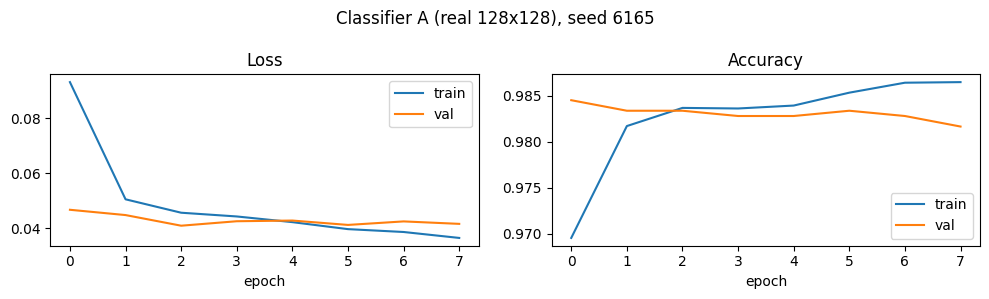

Trainable parameters (head only, K2 A): 524801
Classifier A validation accuracy: 0.9834


In [ ]:
# Model A: classifier on real 128x128 images
clfA, histA = {}, {}
for s in CLASSIFIER_SEEDS:
    clfA[s], histA[s] = train_classifier('A_real', HR, seed=s)
    plot_history(histA[s], f'Classifier A (real 128x128), seed {s}')
CLF_A = clfA[SEED]          # judge for SRGAN checkpoint selection (T7 C)
print('Trainable parameters (head only, K2 A):', count_params(CLF_A, trainable_only=True))
pv = predict_probs(CLF_A, HR, SPLITS['val'])
RESULTS['A_val_acc'] = float(((pv > 0.5) == LABELS[SPLITS['val']]).mean())
print(f"Classifier A validation accuracy: {RESULTS['A_val_acc']:.4f}")

## 4. SRGAN: generator, discriminator and losses (G1–G7, L1–L7)

In [ ]:
def icnr_(weight, scale=2, init=nn.init.kaiming_normal_):
    """G3 A: ICNR init (Aitken et al. 2017) so PixelShuffle starts as nearest-neighbour + conv,
    which removes the checkerboard pattern at initialization."""
    out_ch, in_ch, kh, kw = weight.shape
    sub = torch.empty(out_ch // (scale ** 2), in_ch, kh, kw)
    init(sub, a=0.25, nonlinearity='leaky_relu')
    weight.data.copy_(sub.repeat_interleave(scale ** 2, dim=0))

class ResidualBlock(nn.Module):
    """G2 B: no BatchNorm. G4 A: PReLU. G5 C: Kaiming init scaled by 0.1."""
    def __init__(self, ch):
        super().__init__()
        self.conv1 = nn.Conv2d(ch, ch, 3, 1, 1)
        self.act = nn.PReLU(ch, init=0.25)
        self.conv2 = nn.Conv2d(ch, ch, 3, 1, 1)
        for conv in (self.conv1, self.conv2):
            nn.init.kaiming_normal_(conv.weight, a=0.25, nonlinearity='leaky_relu')
            conv.weight.data.mul_(0.1)                               # G5 C
            nn.init.zeros_(conv.bias)

    def forward(self, x):
        return x + self.conv2(self.act(self.conv1(x)))

class UpsampleBlock(nn.Module):
    """G3 A: conv -> PixelShuffle(2) -> PReLU, ICNR-initialized."""
    def __init__(self, ch):
        super().__init__()
        self.conv = nn.Conv2d(ch, ch * 4, 3, 1, 1)
        icnr_(self.conv.weight); nn.init.zeros_(self.conv.bias)
        self.shuffle = nn.PixelShuffle(2)
        self.act = nn.PReLU(ch, init=0.25)

    def forward(self, x):
        return self.act(self.shuffle(self.conv(x)))

class Generator(nn.Module):
    def __init__(self, n_blocks=N_RES_BLOCKS, ch=G_CHANNELS):
        super().__init__()
        self.head = nn.Sequential(nn.Conv2d(3, ch, 9, 1, 4), nn.PReLU(ch, init=0.25))
        self.trunk = nn.Sequential(*[ResidualBlock(ch) for _ in range(n_blocks)])   # G1 B
        self.trunk_conv = nn.Conv2d(ch, ch, 3, 1, 1)                                 # (no BN, G2 B)
        self.upsample = nn.Sequential(UpsampleBlock(ch), UpsampleBlock(ch))          # x4
        self.tail = nn.Conv2d(ch, 3, 9, 1, 4)
        for conv in (self.head[0], self.trunk_conv, self.tail):
            nn.init.kaiming_normal_(conv.weight, a=0.25, nonlinearity='leaky_relu')
            nn.init.zeros_(conv.bias)

    def forward(self, lr01):                          # D5 A: input LR in [0,1]
        f0 = self.head(lr01)
        h = f0 + self.trunk_conv(self.trunk(f0))      # G6 B: global skip
        return torch.tanh(self.tail(self.upsample(h)))   # G7 A: output in [-1,1]

def sn_conv(cin, cout, stride):
    return [spectral_norm(nn.Conv2d(cin, cout, 3, stride, 1)), nn.LeakyReLU(0.2, inplace=True)]

class Discriminator(nn.Module):
    """L1 A: SRGAN discriminator (8 conv layers 64->512, alternating stride, dense 1024, 1 logit).
    L2 B: spectral norm on every layer instead of BatchNorm."""
    def __init__(self):
        super().__init__()
        cfg = [(3, 64, 1), (64, 64, 2), (64, 128, 1), (128, 128, 2),
               (128, 256, 1), (256, 256, 2), (256, 512, 1), (512, 512, 2)]
        layers = []
        for cin, cout, s in cfg:
            layers += sn_conv(cin, cout, s)
        self.features = nn.Sequential(*layers)
        feat = HR_SIZE // 16
        self.classifier = nn.Sequential(
            nn.Flatten(),
            spectral_norm(nn.Linear(512 * feat * feat, 1024)), nn.LeakyReLU(0.2, inplace=True),
            spectral_norm(nn.Linear(1024, 1)))

    def forward(self, x_m11):                         # input in [-1,1]
        return self.classifier(self.features(x_m11)).squeeze(1)   # logit

class VGGFeatures(nn.Module):
    """L6 B: VGG19 features before the conv5_4 activation (features[:35] ends at conv5_4)."""
    def __init__(self):
        super().__init__()
        weights = VGG19_Weights.IMAGENET1K_V1 if PRETRAINED else None
        self.net = vgg19(weights=weights).features[:35].eval()
        for p in self.net.parameters():
            p.requires_grad = False

    def forward(self, x_m11):
        return self.net(imagenet_norm(to_01(x_m11)))

set_seed()
_G, _D = Generator(), Discriminator()
with torch.no_grad():
    _out = _G(torch.rand(2, 3, LR_SIZE, LR_SIZE))
    assert _out.shape == (2, 3, HR_SIZE, HR_SIZE) and _out.abs().max() <= 1
    assert _D(_out).shape == (2,)
RESULTS['G_params'], RESULTS['D_params'] = count_params(_G), count_params(_D)
print(f"Generator parameters: {RESULTS['G_params']:,} | Discriminator parameters: {RESULTS['D_params']:,}")
del _G, _D, _out

Generator parameters: 1,546,435 | Discriminator parameters: 38,241,857


In [ ]:
bce = nn.BCEWithLogitsLoss()

def d_loss_fn(d_real, d_fake):
    """L3 A vanilla GAN loss, L4 B one-sided label smoothing (real = 0.9, fake = 0)."""
    return bce(d_real.float(), torch.full_like(d_real.float(), REAL_LABEL)) + \
           bce(d_fake.float(), torch.zeros_like(d_fake.float()))

def g_losses(sr, hr_m11, d_fake_for_g, vgg):
    """L5 B pixel L1, L6 B VGG perceptual MSE, L3 A non-saturating adversarial; L7 C weights."""
    pix = F.l1_loss(sr.float(), hr_m11)
    perc = F.mse_loss(vgg(sr).float(), vgg(hr_m11).float().detach())
    adv = bce(d_fake_for_g.float(), torch.ones_like(d_fake_for_g.float()))
    total = W_PIX * pix + W_PERC * perc + W_ADV * adv
    return total, pix, perc, adv

## 5. SRGAN monitoring and checkpoint helpers (T6, T7)

* **T6 B** — every 5 epochs: a G-only snapshot (~6 MB), a full resumable state `latest.pt` (G, D, both optimizers, schedulers, AMP scalers, history, RNG states), and `best.pt` when the T7 metric improves. Saving to a temp file and renaming means a disconnect mid-save cannot corrupt `latest.pt`.
* **T7 C** — at each snapshot, the SRGAN output for the validation images is scored by classifier A. PSNR and SSIM vs. bicubic are logged too.

In [ ]:
def psnr(x01, y01):
    mse = F.mse_loss(x01, y01, reduction='none').mean((1, 2, 3)).clamp_min(1e-10)
    return 10 * torch.log10(1.0 / mse)

def _gauss_window(size=11, sigma=1.5, channels=3):
    g = torch.exp(-(torch.arange(size, dtype=torch.float32) - size // 2) ** 2 / (2 * sigma ** 2))
    g = (g / g.sum()).to(DEVICE)
    return (g[:, None] @ g[None, :]).expand(channels, 1, size, size).contiguous()

_WIN = None
def ssim(x01, y01):
    """SSIM (Wang et al. 2004) with an 11x11 Gaussian window, sigma 1.5, data range 1."""
    global _WIN
    if _WIN is None: _WIN = _gauss_window()
    C1, C2 = 0.01 ** 2, 0.03 ** 2
    mu_x = F.conv2d(x01, _WIN, groups=3); mu_y = F.conv2d(y01, _WIN, groups=3)
    sxx = F.conv2d(x01 * x01, _WIN, groups=3) - mu_x ** 2
    syy = F.conv2d(y01 * y01, _WIN, groups=3) - mu_y ** 2
    sxy = F.conv2d(x01 * y01, _WIN, groups=3) - mu_x * mu_y
    m = ((2 * mu_x * mu_y + C1) * (2 * sxy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sxx + syy + C2))
    return m.mean((1, 2, 3))

@torch.no_grad()
def super_resolve(G, hr_u8_batch):
    """HR uint8 -> LR (D2 A) -> SR in [0,1]."""
    lr = hr_to_lr(u8_to_01(hr_u8_batch))
    with torch.autocast(DEVICE.type, enabled=USE_AMP):
        sr = G(lr)
    return to_01(sr.float()).clamp(0, 1), lr

@torch.no_grad()
def evaluate_sr(G, indices, clf=None, batch_size=64):
    """Mean PSNR/SSIM of SR and bicubic vs HR, plus classifier accuracy on (quantized) SR images."""
    G.eval()
    out = {'psnr_sr': [], 'psnr_bic': [], 'ssim_sr': [], 'ssim_bic': [], 'probs': []}
    for b in batches(indices, batch_size, shuffle=False):
        hr = u8_to_01(HR[b])
        sr, lr = super_resolve(G, HR[b])
        sr = u8_to_01(t01_to_u8(sr))                 # same uint8 quantization B will see
        bic = bicubic_up(lr)
        out['psnr_sr'].append(psnr(sr, hr)); out['psnr_bic'].append(psnr(bic, hr))
        out['ssim_sr'].append(ssim(sr, hr)); out['ssim_bic'].append(ssim(bic, hr))
        if clf is not None:
            clf.eval()
            with torch.autocast(DEVICE.type, enabled=USE_AMP):
                out['probs'].append(torch.sigmoid(clf(imagenet_norm(sr)).float()).cpu())
    res = {k: torch.cat(v).mean().item() for k, v in out.items() if k != 'probs'}
    if clf is not None:
        p = torch.cat(out['probs']).numpy()
        res['clsA_acc'] = float(((p > 0.5) == LABELS[indices]).mean())
    G.train()
    return res

@torch.no_grad()
def save_progress_grid(G, tag):
    """Fixed progress grid: the same 4 cats + 4 dogs every time (LR / bicubic / SR / HR)."""
    G.eval()
    hr = u8_to_01(HR[FIXED_GRID_IDX])
    sr, lr = super_resolve(G, HR[FIXED_GRID_IDX])
    path = P('srgan', 'progress', f'{tag}.png')
    fig, axes = plt.subplots(4, len(FIXED_GRID_IDX), figsize=(2 * len(FIXED_GRID_IDX), 8.4))
    for r, (imgs, name) in enumerate(zip([F.interpolate(lr, size=HR_SIZE, mode='nearest'), bicubic_up(lr), sr, hr],
                                         ['LR (nearest)', 'Bicubic', 'SRGAN', 'HR'])):
        for c in range(len(FIXED_GRID_IDX)):
            axes[r, c].imshow(imgs[c].permute(1, 2, 0).cpu().numpy()); axes[r, c].axis('off')
            if c == 0: axes[r, c].set_title(name, loc='left', fontsize=9)
    fig.suptitle(tag); plt.tight_layout(); plt.savefig(path, dpi=90); plt.close(fig)
    G.train()
    return path

def rng_state():
    return {'torch': torch.get_rng_state(), 'numpy': np.random.get_state(), 'python': random.getstate(),
            'cuda': torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None}

def set_rng_state(s):
    # Checkpoints are loaded with map_location=DEVICE, which moves these byte tensors to the GPU;
    # the RNG setters require CPU ByteTensors, so move them back first.
    torch.set_rng_state(s['torch'].cpu().to(torch.uint8))
    np.random.set_state(s['numpy']); random.setstate(s['python'])
    if s['cuda'] is not None and torch.cuda.is_available():
        torch.cuda.set_rng_state_all([t.cpu().to(torch.uint8) for t in s['cuda']])

## 6. SRGAN stage 1 — pixel-loss warm start (T1 B)

20 epochs with the L1 pixel loss only. This gives the GAN a faithful starting point, and the result is saved as an extra model (`pretrain_final_G.pt`). Resumes from `pretrain_latest.pt` after a disconnect.

In [ ]:
_needed = ['P', 'HR', 'SPLITS', 'Generator', 'evaluate_sr']
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Missing {_missing}: the kernel restarted (new Colab session). Click this cell and use "
                       "Runtime -> Run before (Ctrl+F8), then run it again. Earlier stages reload from Drive "
                       "in a few minutes instead of retraining.")

PRE_LATEST, PRE_FINAL = P('srgan', 'pretrain_latest.pt'), P('srgan', 'pretrain_final_G.pt')

def train_epoch_pixel(G, opt, scaler, epoch_seed):
    G.train(); total, n = 0.0, 0
    for b in batches(SPLITS['train'], SR_BATCH, shuffle=True, epoch_seed=epoch_seed):
        hr = random_hflip(u8_to_01(HR[b]))          # D4 B: flip HR, then derive LR from it
        lr = hr_to_lr(hr)                            # D2 A
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            sr = G(lr)
        loss = F.l1_loss(sr.float(), to_m11(hr))     # L5 B
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
        total += loss.item() * len(b); n += len(b)
    return total / n

set_seed()
G = Generator().to(DEVICE)
if os.path.exists(PRE_FINAL):
    G.load_state_dict(torch.load(PRE_FINAL, map_location=DEVICE))
    print('Warm start already finished: loaded', PRE_FINAL)
else:
    opt_pre = torch.optim.Adam(G.parameters(), lr=GAN_LR, betas=ADAM_BETAS)      # T2 A
    scaler_pre = torch.amp.GradScaler('cuda', enabled=USE_AMP)                   # T5 B
    start, pre_hist = 1, []
    if os.path.exists(PRE_LATEST):
        ck = torch.load(PRE_LATEST, map_location=DEVICE, weights_only=False)
        G.load_state_dict(ck['G']); opt_pre.load_state_dict(ck['opt']); scaler_pre.load_state_dict(ck['scaler'])
        start, pre_hist = ck['epoch'] + 1, ck['history']; set_rng_state(ck['rng'])
        print(f'Resuming warm start from epoch {start}')
    for epoch in range(start, PRETRAIN_EPOCHS + 1):
        t0 = time.time()
        loss = train_epoch_pixel(G, opt_pre, scaler_pre, epoch_seed=SEED + epoch)
        pre_hist.append({'epoch': epoch, 'l1': loss})
        msg = f'[warm start] epoch {epoch}/{PRETRAIN_EPOCHS}  L1 {loss:.4f}  ({time.time() - t0:.0f}s)'
        if epoch % SAVE_EVERY == 0 or epoch == PRETRAIN_EPOCHS:
            ev = evaluate_sr(G, SPLITS['val'])
            pre_hist[-1].update(ev)
            msg += f"  | val PSNR SR {ev['psnr_sr']:.2f} dB vs bicubic {ev['psnr_bic']:.2f} dB"
            atomic_save({'G': G.state_dict(), 'opt': opt_pre.state_dict(), 'scaler': scaler_pre.state_dict(),
                         'epoch': epoch, 'history': pre_hist, 'rng': rng_state()}, PRE_LATEST)
        print(msg)
    atomic_save(G.state_dict(), PRE_FINAL)
    save_progress_grid(G, 'pretrain_final')
    print('Saved', PRE_FINAL)

Warm start already finished: loaded /content/drive/My Drive/srgan_midterm/srgan/pretrain_final_G.pt


## 7. SRGAN stage 2 — adversarial training, 150 epochs (T2–T6)

Each batch: one discriminator step, then one generator step (k = 1). Losses are logged per term so their balance (L7) can be checked. Learning rates drop ×0.1 at GAN epoch 100 (T3 B). Re-running this cell resumes from `latest.pt`.

In [ ]:
_needed = ['P', 'HR', 'SPLITS', 'Generator', 'Discriminator', 'VGGFeatures', 'CLF_A', 'PRE_FINAL', 'evaluate_sr']
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Missing {_missing}: the kernel restarted (new Colab session). Click this cell and use "
                       "Runtime -> Run before (Ctrl+F8), then run it again. Earlier stages reload from Drive "
                       "in a few minutes instead of retraining.")

LATEST, BEST = P('srgan', 'latest.pt'), P('srgan', 'best.pt')
LOG_CSV = P('srgan', 'gan_log.csv')

set_seed()
G = Generator().to(DEVICE)
G.load_state_dict(torch.load(PRE_FINAL, map_location=DEVICE))   # T1 B: start from warm-started G
D = Discriminator().to(DEVICE)
vgg = VGGFeatures().to(DEVICE)
optG = torch.optim.Adam(G.parameters(), lr=GAN_LR, betas=ADAM_BETAS)           # T2 A
optD = torch.optim.Adam(D.parameters(), lr=GAN_LR, betas=ADAM_BETAS)
schG = torch.optim.lr_scheduler.MultiStepLR(optG, milestones=[LR_DROP_EPOCH], gamma=0.1)   # T3 B
schD = torch.optim.lr_scheduler.MultiStepLR(optD, milestones=[LR_DROP_EPOCH], gamma=0.1)
scalerG = torch.amp.GradScaler('cuda', enabled=USE_AMP)                         # T5 B
scalerD = torch.amp.GradScaler('cuda', enabled=USE_AMP)
start_epoch, gan_hist, snap_hist, best_acc = 1, [], [], -1.0

if os.path.exists(LATEST):
    ck = torch.load(LATEST, map_location=DEVICE, weights_only=False)
    G.load_state_dict(ck['G']); D.load_state_dict(ck['D'])
    optG.load_state_dict(ck['optG']); optD.load_state_dict(ck['optD'])
    schG.load_state_dict(ck['schG']); schD.load_state_dict(ck['schD'])
    scalerG.load_state_dict(ck['scalerG']); scalerD.load_state_dict(ck['scalerD'])
    start_epoch, gan_hist, snap_hist, best_acc = ck['epoch'] + 1, ck['gan_hist'], ck['snap_hist'], ck['best_acc']
    set_rng_state(ck['rng'])
    print(f'Resuming GAN training from epoch {start_epoch}')

for epoch in range(start_epoch, GAN_EPOCHS + 1):
    G.train(); D.train(); t0 = time.time()
    sums = dict(d_loss=0., g_total=0., pix=0., perc=0., adv=0., d_real=0., d_fake=0.); n = 0
    for b in batches(SPLITS['train'], SR_BATCH, shuffle=True, epoch_seed=SEED + 10_000 + epoch):   # T4 B
        hr01 = random_hflip(u8_to_01(HR[b]))            # D4 B
        lr = hr_to_lr(hr01)                              # D2 A, LR in [0,1] (D5 A)
        hr = to_m11(hr01)                                # D5 A, HR in [-1,1]

        # --- discriminator step ---
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            sr = G(lr)
            d_real, d_fake = D(hr), D(sr.detach())
            d_loss = d_loss_fn(d_real, d_fake)           # L3 A + L4 B
        optD.zero_grad(set_to_none=True)
        scalerD.scale(d_loss).backward(); scalerD.step(optD); scalerD.update()

        # --- generator step ---
        with torch.autocast(DEVICE.type, enabled=USE_AMP):
            g_total, pix, perc, adv = g_losses(sr, hr, D(sr), vgg)   # L5-L7
        optG.zero_grad(set_to_none=True)
        scalerG.scale(g_total).backward(); scalerG.step(optG); scalerG.update()

        k = len(b); n += k
        for name, val in [('d_loss', d_loss), ('g_total', g_total), ('pix', pix), ('perc', perc), ('adv', adv),
                          ('d_real', torch.sigmoid(d_real.float()).mean()), ('d_fake', torch.sigmoid(d_fake.float()).mean())]:
            sums[name] += val.item() * k
    schG.step(); schD.step()
    row = {'epoch': epoch, 'lr': optG.param_groups[0]['lr'], 'sec': round(time.time() - t0, 1),
           **{k: v / n for k, v in sums.items()}}
    gan_hist.append(row)
    print(f"[GAN] epoch {epoch:3d}/{GAN_EPOCHS}  D {row['d_loss']:.3f} | G {row['g_total']:.4f} "
          f"(pix {row['pix']:.4f}, perc {row['perc']:.3f}, adv {row['adv']:.3f}) | "
          f"D(real) {row['d_real']:.2f} D(fake) {row['d_fake']:.2f} | {row['sec']:.0f}s")

    if epoch % SAVE_EVERY == 0 or epoch == GAN_EPOCHS:                              # T6 B
        ev = evaluate_sr(G, SPLITS['val'], clf=CLF_A)                                # T7 C metric
        snap_path = P('srgan', 'snapshots', f'G_epoch{epoch:03d}.pt')
        atomic_save(G.state_dict(), snap_path)
        snap_hist.append({'epoch': epoch, 'path': snap_path, **ev})
        save_progress_grid(G, f'epoch_{epoch:03d}')
        print(f"      snapshot: val clsA acc {ev['clsA_acc']:.4f} | PSNR SR {ev['psnr_sr']:.2f} vs bic {ev['psnr_bic']:.2f} dB"
              f" | SSIM SR {ev['ssim_sr']:.3f} vs bic {ev['ssim_bic']:.3f}")
        state = {'G': G.state_dict(), 'D': D.state_dict(), 'optG': optG.state_dict(), 'optD': optD.state_dict(),
                 'schG': schG.state_dict(), 'schD': schD.state_dict(),
                 'scalerG': scalerG.state_dict(), 'scalerD': scalerD.state_dict(),
                 'epoch': epoch, 'gan_hist': gan_hist, 'snap_hist': snap_hist, 'best_acc': best_acc, 'rng': rng_state()}
        if ev['clsA_acc'] > best_acc:
            best_acc = state['best_acc'] = ev['clsA_acc']
            atomic_save(state, BEST)
        atomic_save(state, LATEST)
        pd.DataFrame(gan_hist).to_csv(LOG_CSV, index=False)

print('GAN training complete:', len(gan_hist), 'epochs logged')

Downloading: "https://download.pytorch.org/models/vgg19-dcbb9e9d.pth" to /root/.cache/torch/hub/checkpoints/vgg19-dcbb9e9d.pth


100%|██████████| 548M/548M [00:07<00:00, 75.0MB/s]


Resuming GAN training from epoch 151
GAN training complete: 150 epochs logged


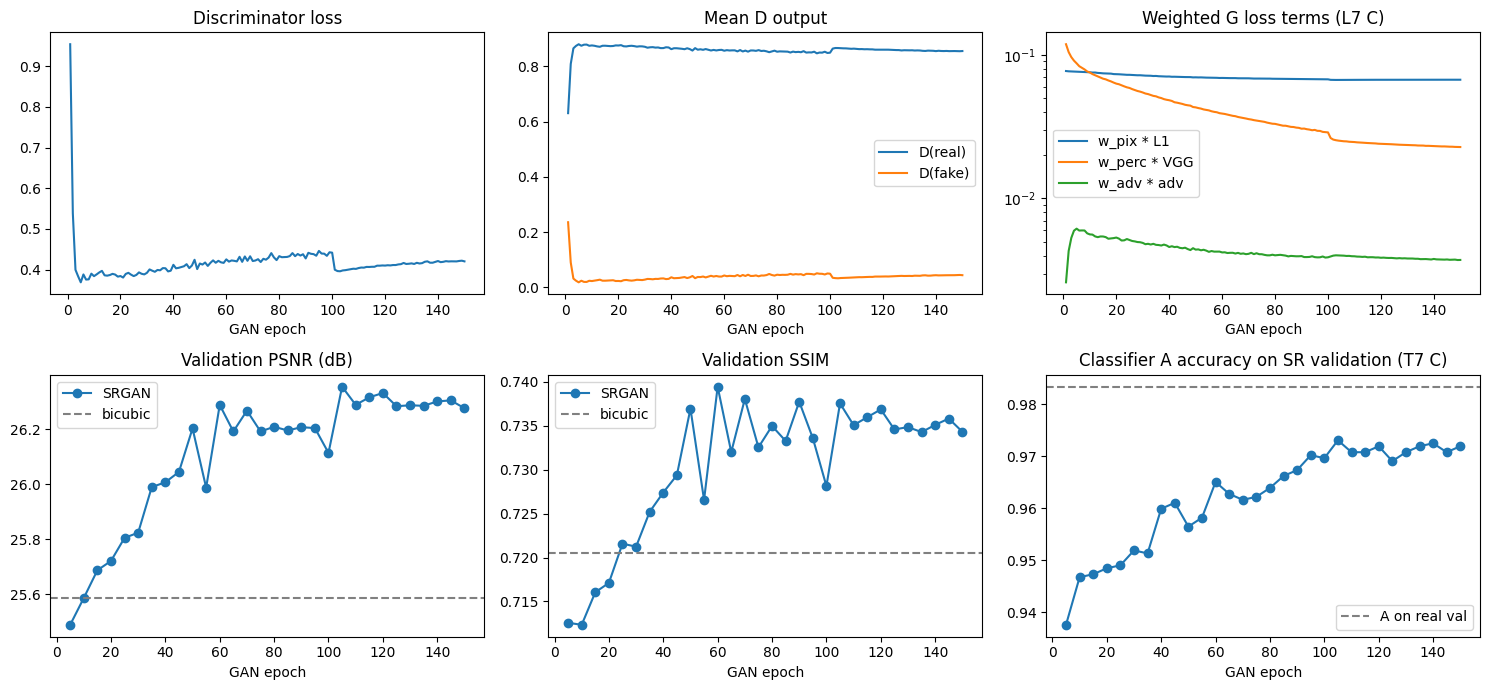

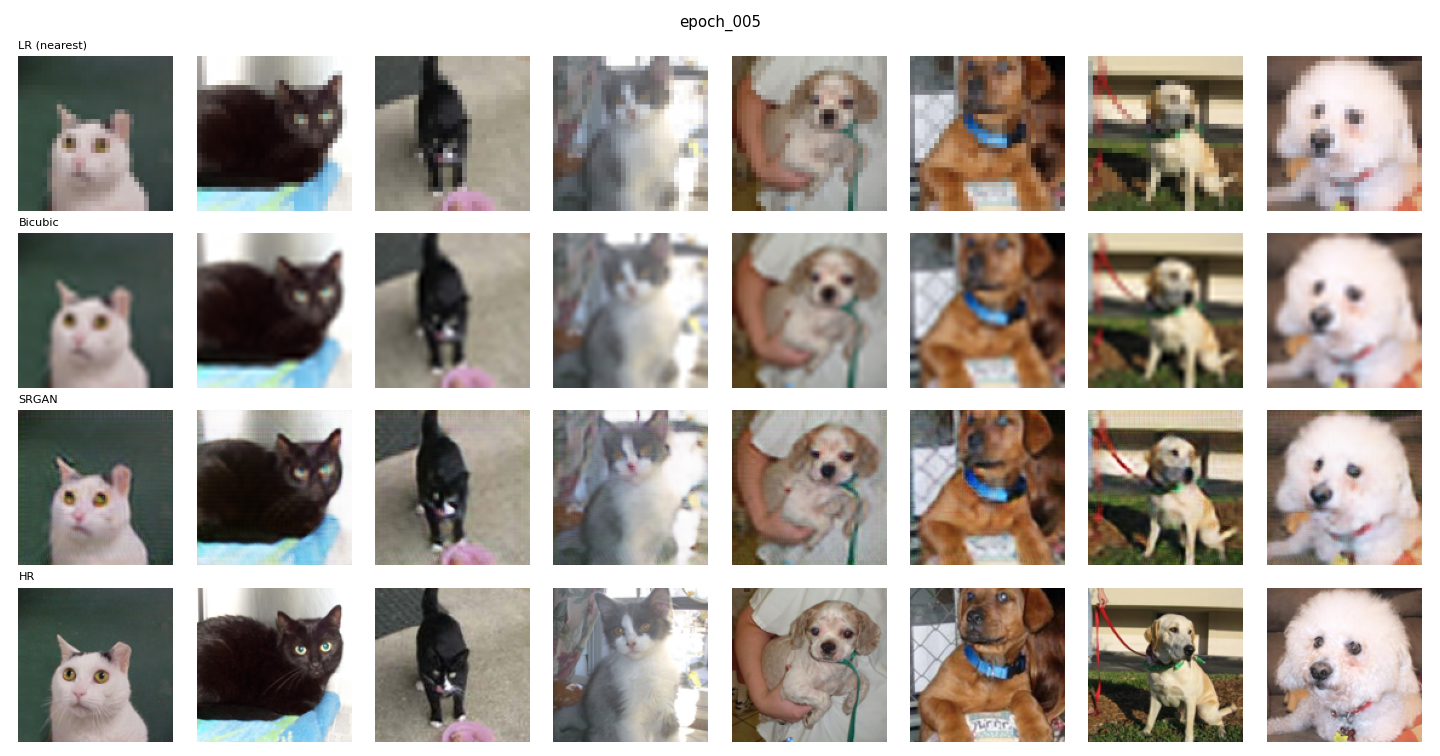

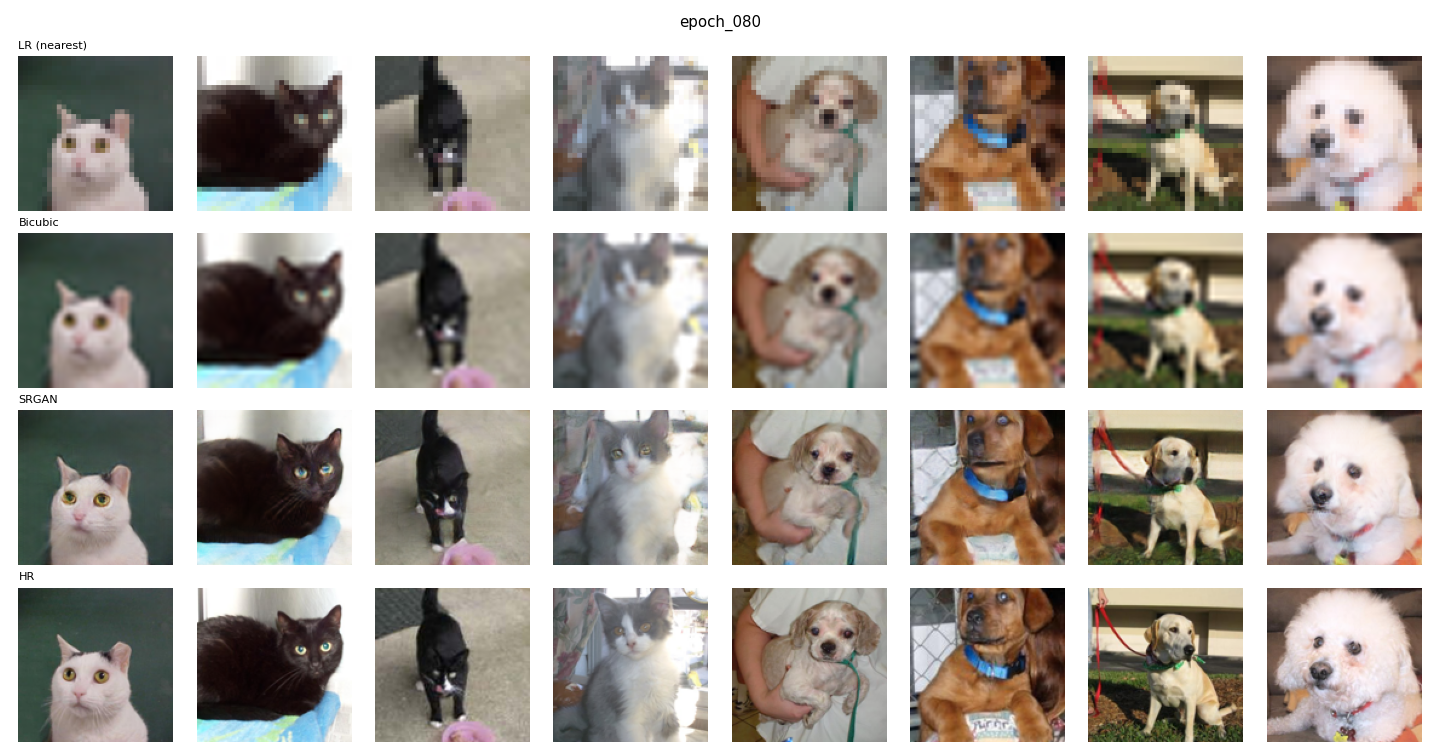

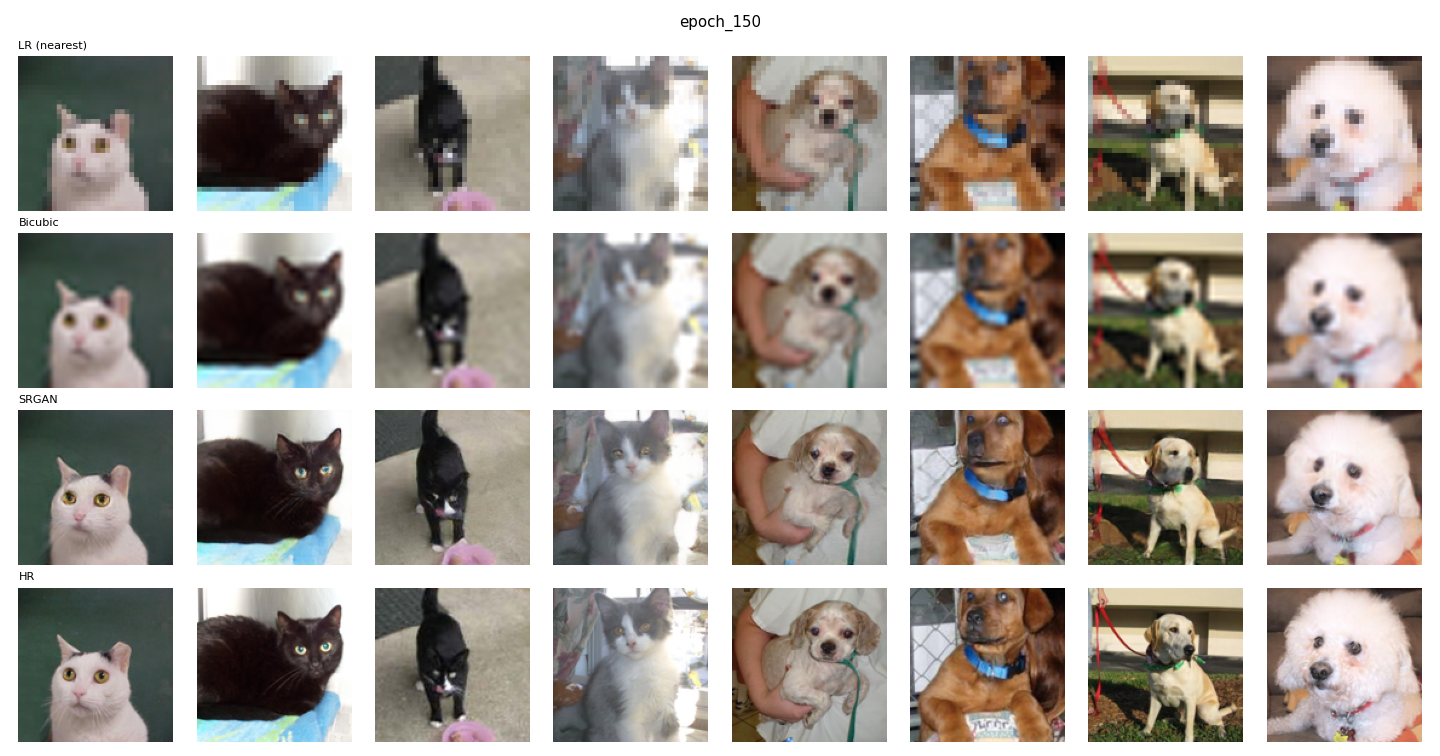

In [ ]:
# Loss curves and validation metrics
gh = pd.DataFrame(gan_hist); sh = pd.DataFrame(snap_hist)
fig, ax = plt.subplots(2, 3, figsize=(15, 7))
ax[0, 0].plot(gh.epoch, gh.d_loss); ax[0, 0].set_title('Discriminator loss')
ax[0, 1].plot(gh.epoch, gh.d_real, label='D(real)'); ax[0, 1].plot(gh.epoch, gh.d_fake, label='D(fake)')
ax[0, 1].set_title('Mean D output'); ax[0, 1].legend()
ax[0, 2].plot(gh.epoch, W_PIX * gh.pix, label='w_pix * L1'); ax[0, 2].plot(gh.epoch, W_PERC * gh.perc, label='w_perc * VGG')
ax[0, 2].plot(gh.epoch, W_ADV * gh.adv, label='w_adv * adv'); ax[0, 2].set_title('Weighted G loss terms (L7 C)')
ax[0, 2].set_yscale('log'); ax[0, 2].legend()
ax[1, 0].plot(sh.epoch, sh.psnr_sr, 'o-', label='SRGAN'); ax[1, 0].axhline(sh.psnr_bic.iloc[0], ls='--', c='gray', label='bicubic')
ax[1, 0].set_title('Validation PSNR (dB)'); ax[1, 0].legend()
ax[1, 1].plot(sh.epoch, sh.ssim_sr, 'o-', label='SRGAN'); ax[1, 1].axhline(sh.ssim_bic.iloc[0], ls='--', c='gray', label='bicubic')
ax[1, 1].set_title('Validation SSIM'); ax[1, 1].legend()
ax[1, 2].plot(sh.epoch, sh.clsA_acc, 'o-'); ax[1, 2].axhline(RESULTS['A_val_acc'], ls='--', c='gray', label='A on real val')
ax[1, 2].set_title('Classifier A accuracy on SR validation (T7 C)'); ax[1, 2].legend()
for a in ax.flat: a.set_xlabel('GAN epoch')
plt.tight_layout(); plt.savefig(P('figures', 'srgan_training_curves.png'), dpi=110); plt.show()

from IPython.display import Image as IPImage, display
grids = sorted(glob.glob(P('srgan', 'progress', 'epoch_*.png')))
for g in [grids[0], grids[len(grids) // 2], grids[-1]] if len(grids) >= 3 else grids:
    display(IPImage(filename=g))

In [ ]:
_needed = ['P', 'snap_hist', 'Generator']
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Missing {_missing}: the kernel restarted (new Colab session). Click this cell and use "
                       "Runtime -> Run before (Ctrl+F8), then run it again. Earlier stages reload from Drive "
                       "in a few minutes instead of retraining.")

# T7 C: choose the generator checkpoint by classifier-A accuracy on SR validation images.
# Checkpoints within TIE_TOLERANCE accuracy points of the best are treated as tied; the latest wins.
sh = pd.DataFrame(snap_hist)
best = sh.clsA_acc.max()
tied = sh[sh.clsA_acc >= best - TIE_TOLERANCE / 100]
chosen = tied.sort_values('epoch').iloc[-1]
display(sh[['epoch', 'clsA_acc', 'psnr_sr', 'psnr_bic', 'ssim_sr', 'ssim_bic']].round(4))
print(f"Best val accuracy {best:.4f}; {len(tied)} checkpoint(s) within {TIE_TOLERANCE} point(s).")
print(f"Chosen generator: epoch {int(chosen.epoch)} (val clsA acc {chosen.clsA_acc:.4f}, PSNR {chosen.psnr_sr:.2f} dB)")
RESULTS['T7_chosen_epoch'] = int(chosen.epoch)
RESULTS['T7_chosen_val_acc'] = float(chosen.clsA_acc)

G_FINAL = Generator().to(DEVICE)
G_FINAL.load_state_dict(torch.load(chosen.path, map_location=DEVICE))
_ = G_FINAL.eval()

,epoch,clsA_acc,psnr_sr,psnr_bic,ssim_sr,ssim_bic
0,5,0.9376,25.4895,25.5856,0.7126,0.7205
1,10,0.9467,25.5870,25.5856,0.7123,0.7205
2,15,0.9473,25.6879,25.5856,0.7160,0.7205
3,20,0.9485,25.7217,25.5856,0.7171,0.7205
4,25,0.9490,25.8058,25.5856,0.7216,0.7205
5,30,0.9519,25.8244,25.5856,0.7212,0.7205
6,35,0.9513,25.9903,25.5856,0.7252,0.7205
7,40,0.9599,26.0078,25.5856,0.7274,0.7205
8,45,0.9611,26.0455,25.5856,0.7294,0.7205
9,50,0.9565,26.2037,25.5856,0.7370,0.7205


Best val accuracy 0.9731; 16 checkpoint(s) within 1.0 point(s).
Chosen generator: epoch 150 (val clsA acc 0.9719, PSNR 26.28 dB)


## 8. Generate the image sets for models B and C

Every image (train, validation and test) is downscaled to 32×32 with the same function (D2 A), then:

* **SR set (model B):** upscaled by the chosen SRGAN generator.
* **Bicubic set (model C):** upscaled by plain bicubic interpolation.

Both are stored as uint8 arrays on Drive, quantized exactly like the real images.

Loaded cached SR and bicubic sets


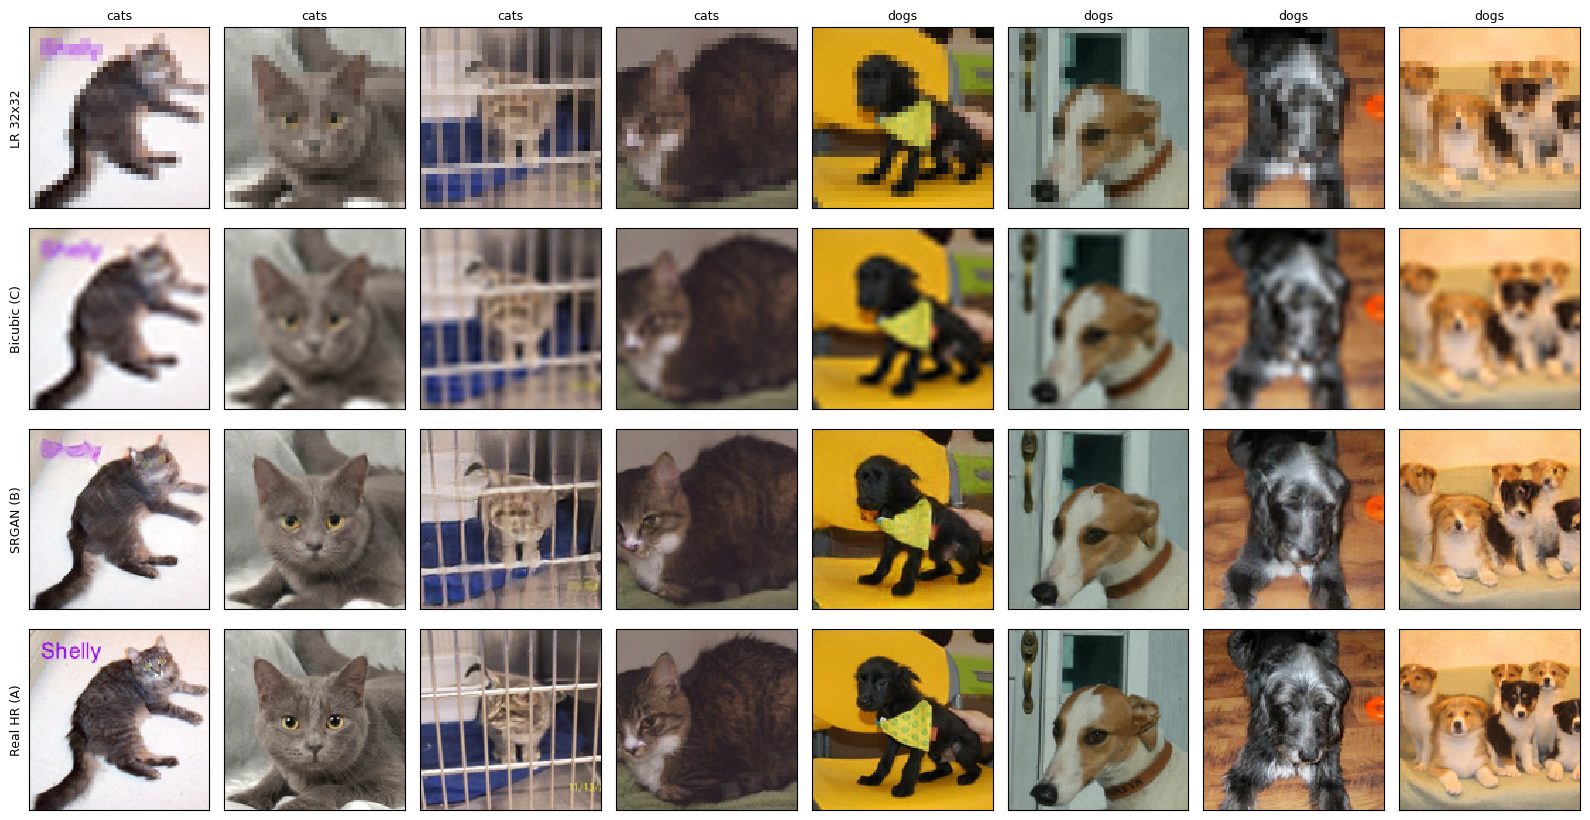

,PSNR (dB),SSIM
SRGAN,26.2435,0.7364
Bicubic,25.4955,0.7204


In [ ]:
_needed = ['P', 'HR', 'G_FINAL', 'RESULTS']
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Missing {_missing}: the kernel restarted (new Colab session). Click this cell and use "
                       "Runtime -> Run before (Ctrl+F8), then run it again. Earlier stages reload from Drive "
                       "in a few minutes instead of retraining.")

SR_CACHE = P('cache', f'sr_uint8_epoch{RESULTS["T7_chosen_epoch"]:03d}.npy')
BIC_CACHE = P('cache', 'bicubic_uint8.npy')

@torch.no_grad()
def build_sets(batch_size=128):
    SR = np.empty_like(HR); BIC = np.empty_like(HR)
    for b in batches(np.arange(len(HR)), batch_size, shuffle=False):
        sr, lr = super_resolve(G_FINAL, HR[b])
        SR[b] = t01_to_u8(sr); BIC[b] = t01_to_u8(bicubic_up(lr))
    return SR, BIC

if os.path.exists(SR_CACHE) and os.path.exists(BIC_CACHE):
    SR, BIC = np.load(SR_CACHE), np.load(BIC_CACHE)
    print('Loaded cached SR and bicubic sets')
else:
    t0 = time.time(); SR, BIC = build_sets()
    np.save(SR_CACHE, SR); np.save(BIC_CACHE, BIC)
    print(f'Generated SR and bicubic sets for {len(HR)} images in {time.time() - t0:.0f}s')

ex = np.concatenate([idx_test[LABELS[idx_test] == 0][:4], idx_test[LABELS[idx_test] == 1][:4]])
lr_ex = hr_to_lr(u8_to_01(HR[ex]))
show_rows([F.interpolate(lr_ex, size=HR_SIZE, mode='nearest'), u8_to_01(BIC[ex]), u8_to_01(SR[ex]), u8_to_01(HR[ex])],
          ['LR 32x32', 'Bicubic (C)', 'SRGAN (B)', 'Real HR (A)'],
          [CLASS_NAMES[l] for l in LABELS[ex]], path=P('figures', 'test_examples_bic_sr_hr.png'))

# Image-quality metrics on the test split
q = {'psnr': [[], []], 'ssim': [[], []]}
for b in batches(idx_test, 256, shuffle=False):
    hr = u8_to_01(HR[b])
    for i, src in enumerate([SR, BIC]):
        x = u8_to_01(src[b])
        q['psnr'][i].append(psnr(x, hr)); q['ssim'][i].append(ssim(x, hr))
quality = pd.DataFrame({'PSNR (dB)': [torch.cat(v).mean().item() for v in q['psnr']],
                        'SSIM': [torch.cat(v).mean().item() for v in q['ssim']]}, index=['SRGAN', 'Bicubic']).round(4)
RESULTS['quality'] = quality.to_dict()
display(quality)

## 9. Train models B and C with the identical recipe

[B_srgan_ep150] loaded saved model (best epoch 13)


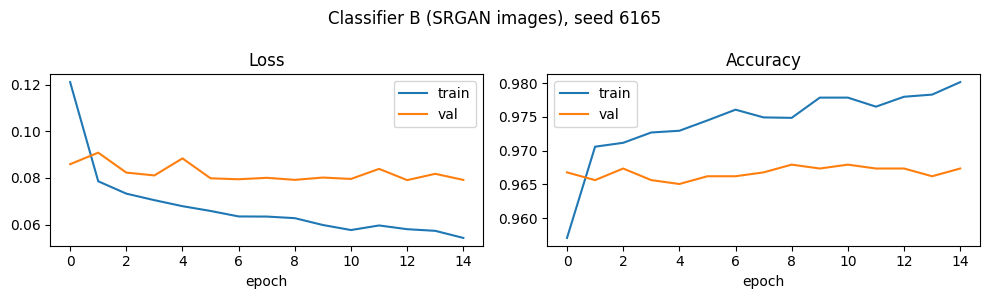

[C_bicubic] loaded saved model (best epoch 15)


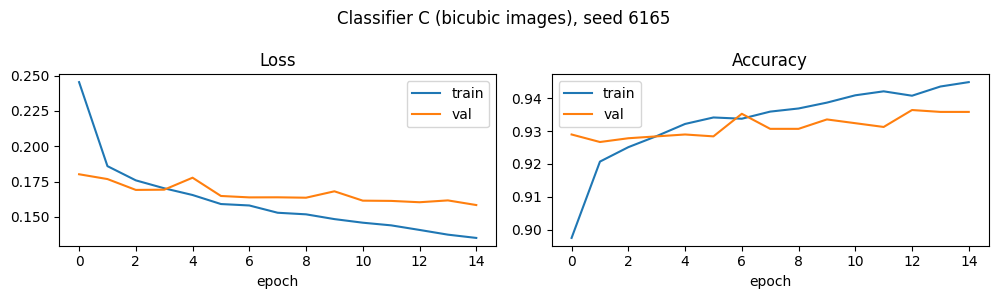

In [ ]:
_needed = ['SR', 'BIC', 'train_classifier', 'RESULTS']
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Missing {_missing}: the kernel restarted (new Colab session). Click this cell and use "
                       "Runtime -> Run before (Ctrl+F8), then run it again. Earlier stages reload from Drive "
                       "in a few minutes instead of retraining.")

clfB, histB, clfC, histC = {}, {}, {}, {}
for s in CLASSIFIER_SEEDS:
    # B's saved model is tied to the chosen generator epoch, so a different T7 choice retrains B
    clfB[s], histB[s] = train_classifier(f'B_srgan_ep{RESULTS["T7_chosen_epoch"]:03d}', SR, seed=s)
    plot_history(histB[s], f'Classifier B (SRGAN images), seed {s}')
    clfC[s], histC[s] = train_classifier('C_bicubic', BIC, seed=s)
    plot_history(histC[s], f'Classifier C (bicubic images), seed {s}')

## 10. Evaluation on the 30% test split (K9 C)

Accuracy, F1 (dog = positive class) and AUC with 95% bootstrap intervals, confusion matrices and ROC curves. All models are scored on the same test images, so McNemar's exact test compares them pairwise.

In [ ]:
_needed = ['clfA', 'clfB', 'clfC', 'HR', 'SR', 'BIC', 'SPLITS']
_missing = [n for n in _needed if n not in globals()]
if _missing:
    raise RuntimeError(f"Missing {_missing}: the kernel restarted (new Colab session). Click this cell and use "
                       "Runtime -> Run before (Ctrl+F8), then run it again. Earlier stages reload from Drive "
                       "in a few minutes instead of retraining.")

def metrics(y, p, n_boot=1000, seed=SEED):
    pred = (p > 0.5).astype(int)
    out = {'Accuracy': accuracy_score(y, pred), 'F1 (dog)': f1_score(y, pred), 'AUC': roc_auc_score(y, p)}
    rng = np.random.default_rng(seed); boots = {k: [] for k in out}
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if len(np.unique(y[i])) < 2: continue
        boots['Accuracy'].append(accuracy_score(y[i], pred[i])); boots['F1 (dog)'].append(f1_score(y[i], pred[i]))
        boots['AUC'].append(roc_auc_score(y[i], p[i]))
    ci = {k + ' 95% CI': f'[{np.percentile(v, 2.5):.4f}, {np.percentile(v, 97.5):.4f}]' for k, v in boots.items()}
    rec = confusion_matrix(y, pred, normalize='true').diagonal()
    return {**out, **ci, 'Cat recall': rec[0], 'Dog recall': rec[1]}

y_test = LABELS[idx_test]
PAIRINGS = [  # K9 C: B tested on both SR and real images; (name, model dict, test image source)
    ('A: real -> real', clfA, HR), ('B: SRGAN -> SRGAN', clfB, SR), ('B: SRGAN -> real', clfB, HR),
    ('C: bicubic -> bicubic', clfC, BIC), ('A: real -> SRGAN (diagnostic)', clfA, SR),
    ('A: real -> bicubic (diagnostic)', clfA, BIC)]
PROBS, rows = {}, []
for name, models, src in PAIRINGS:
    for s, m in models.items():
        p = predict_probs(m, src, idx_test)
        PROBS[(name, s)] = p
        rows.append({'Pairing': name, 'Seed': s, **metrics(y_test, p)})
results_df = pd.DataFrame(rows)
results_df.to_csv(P('figures', 'test_results.csv'), index=False)
num = ['Accuracy', 'F1 (dog)', 'AUC', 'Cat recall', 'Dog recall']
display(results_df.round(4))
if len(CLASSIFIER_SEEDS) > 1:
    display(results_df.groupby('Pairing')[num].agg(['mean', 'std']).round(4))
RESULTS['test'] = results_df.groupby('Pairing')[num].mean().round(4).to_dict('index')

,Pairing,Seed,Accuracy,F1 (dog),AUC,Accuracy 95% CI,F1 (dog) 95% CI,AUC 95% CI,Cat recall,Dog recall
0,A: real -> real,6165,0.9830,0.9830,0.9987,"[0.9801, 0.9858]","[0.9798, 0.9858]","[0.9981, 0.9991]",0.9856,0.9805
1,B: SRGAN -> SRGAN,6165,0.9687,0.9686,0.9959,"[0.9647, 0.9725]","[0.9645, 0.9724]","[0.9951, 0.9967]",0.9725,0.9649
2,B: SRGAN -> real,6165,0.9838,0.9838,0.9988,"[0.9809, 0.9866]","[0.9809, 0.9866]","[0.9983, 0.9992]",0.9832,0.9845
3,C: bicubic -> bicubic,6165,0.9307,0.9299,0.9835,"[0.9254, 0.9361]","[0.9242, 0.9354]","[0.9816, 0.9854]",0.9415,0.9200
4,A: real -> SRGAN (diagnostic),6165,0.9655,0.9652,0.9949,"[0.9615, 0.9698]","[0.9609, 0.9695]","[0.9938, 0.9958]",0.9746,0.9564
5,A: real -> bicubic (diagnostic),6165,0.9020,0.9047,0.9724,"[0.8956, 0.9085]","[0.8980, 0.9109]","[0.9697, 0.9752]",0.8731,0.9310


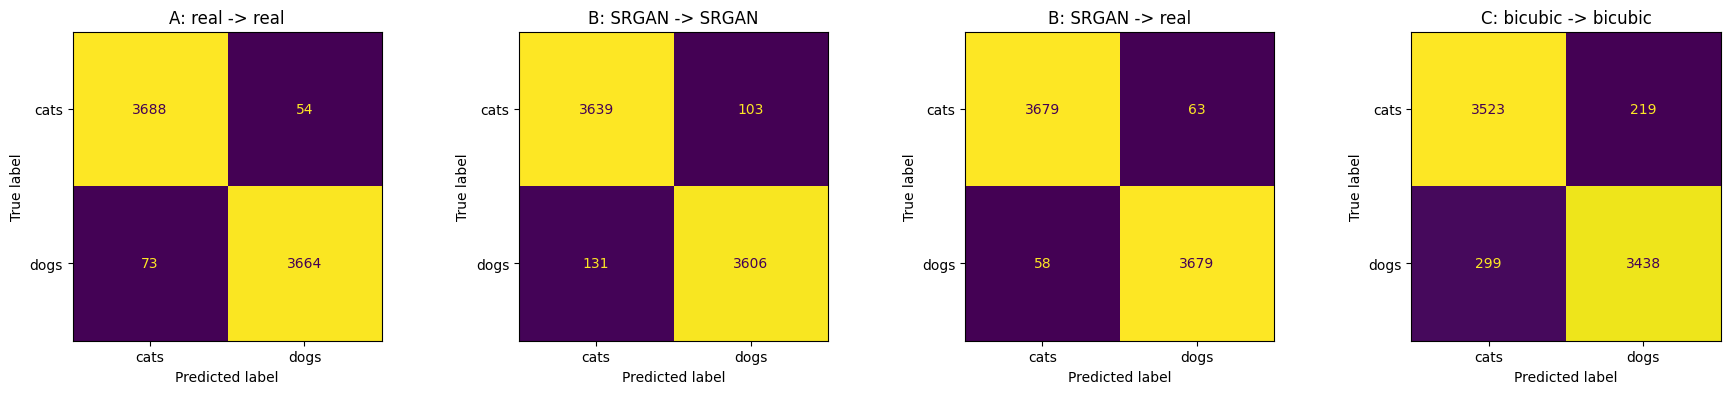

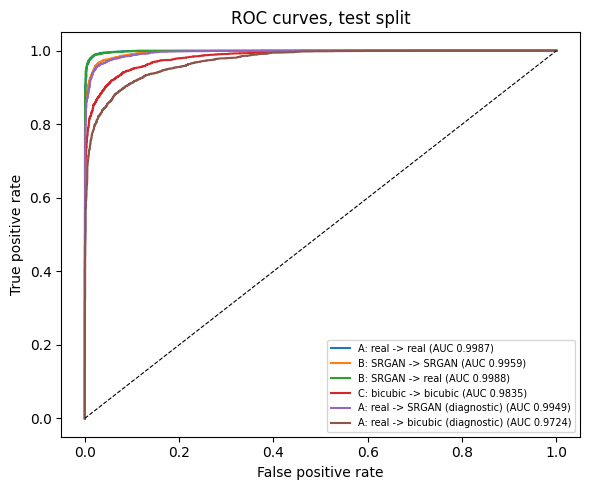

,Comparison,only first correct,only second correct,p-value
0,A: real -> real vs B: SRGAN -> SRGAN,164,57,3.413788e-13
1,B: SRGAN -> SRGAN vs C: bicubic -> bicubic,387,103,1.010877e-39
2,A: real -> real vs C: bicubic -> bicubic,445,54,1.529503e-77


In [ ]:
main = ['A: real -> real', 'B: SRGAN -> SRGAN', 'B: SRGAN -> real', 'C: bicubic -> bicubic']
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, name in zip(axes, main):
    p = PROBS[(name, SEED)]
    ConfusionMatrixDisplay(confusion_matrix(y_test, (p > 0.5).astype(int)),
                           display_labels=CLASS_NAMES).plot(ax=ax, colorbar=False, values_format='d')
    ax.set_title(name)
plt.tight_layout(); plt.savefig(P('figures', 'confusion_matrices.png'), dpi=110); plt.show()

plt.figure(figsize=(6, 5))
for name, _, _ in PAIRINGS:
    fpr, tpr, _ = roc_curve(y_test, PROBS[(name, SEED)])
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_test, PROBS[(name, SEED)]):.4f})")
plt.plot([0, 1], [0, 1], 'k--', lw=0.8)
plt.xlabel('False positive rate'); plt.ylabel('True positive rate'); plt.title('ROC curves, test split')
plt.legend(fontsize=7); plt.tight_layout(); plt.savefig(P('figures', 'roc_curves.png'), dpi=110); plt.show()

def mcnemar(name1, name2):
    c1 = (PROBS[(name1, SEED)] > 0.5) == y_test; c2 = (PROBS[(name2, SEED)] > 0.5) == y_test
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())
    p = binomtest(min(b, c), b + c, 0.5).pvalue if b + c > 0 else 1.0
    return {'Comparison': f'{name1}  vs  {name2}', 'only first correct': b, 'only second correct': c, 'p-value': p}

sig = pd.DataFrame([mcnemar('A: real -> real', 'B: SRGAN -> SRGAN'),
                    mcnemar('B: SRGAN -> SRGAN', 'C: bicubic -> bicubic'),
                    mcnemar('A: real -> real', 'C: bicubic -> bicubic')])
RESULTS['mcnemar'] = sig.to_dict('records')
display(sig)

## 11. Results workbook (one row per decision, 7 lab columns)

The hypotheses are drafts written before running. Edit them to your own words, then fill **Hypothesis Supported?** and **Interpretation** once you have read the results. The file is exported to `Midterm_Results.xlsx` on Drive.

In [28]:
R, T = RESULTS, RESULTS.get('test', {})
acc = lambda k: f"{T[k]['Accuracy']:.4f}" if k in T else 'n/a'
qual = R.get('quality', {})
psnr_txt = (f"Test PSNR SRGAN {qual['PSNR (dB)']['SRGAN']:.2f} dB vs bicubic {qual['PSNR (dB)']['Bicubic']:.2f} dB"
            if qual else 'see section 8')
gap_txt = (f"Test acc A {acc('A: real -> real')}, B {acc('B: SRGAN -> SRGAN')}, C {acc('C: bicubic -> bicubic')}")

rows = [
 ('D1 Non-square photo -> 128x128', 'B - resize shorter side to 128, center crop',
  'Keeps animal proportions; few heads cropped off.', 'PIL bicubic resize, then 128x128 center crop', 'See scaled_examples.png'),
 ('D2 Degradation 128->32', 'A - bicubic with antialiasing',
  'Clean low-pass; no aliasing; comparable with the SRGAN literature.', 'F.interpolate bicubic, antialias=True', psnr_txt),
 ('D3 Data loading and caching', 'A - decode once, cache uint8 HR, LR on the fly',
  'Lossless and much faster than decoding JPEGs every epoch.', 'hr_uint8.npy on Drive', f"{sum(R['split_counts'].values())} images cached"),
 ('D4 SR-pair augmentation', 'B - paired random horizontal flip',
  'Exact pixel permutation: more variety without blur.', 'Flip HR, then derive LR from it', 'See transformed_examples.png'),
 ('D5 Value ranges', 'A - LR [0,1], HR [-1,1]', 'Paper loss weights stay meaningful.', 'to_m11 / to_01 helpers', 'Ranges printed in section 2'),
 ('D6 Tiny originals', 'C - keep, report count', 'Few originals are under 128 px.', 'Shorter side < 128 counted',
  f"{R.get('D6_small_count', 'n/a')} images under 128 px"),
 ('K0 Framework', 'B - PyTorch', 'One framework keeps A, B, C identical.', 'torch / torchvision', 'Fixed setting; not measured separately'),
 ('K1 Backbone', 'C - ResNet50', 'Strong ImageNet features; independent of the VGG loss.', 'torchvision resnet50 IMAGENET1K_V1', gap_txt),
 ('K2 Fine-tuning', 'A - frozen base', 'Measures class evidence for fixed ImageNet features.', 'requires_grad False, BN in eval', 'Head-only training'),
 ('K3 Head', 'A - GAP->Dense256->Dropout0.5->Dense1', 'Matches Assignment 1.', 'BCEWithLogitsLoss', 'Fixed setting; not measured separately'),
 ('K4 Input preprocessing', 'B - ImageNet mean/std', 'Fixes Assignment 1 rescale-only bug; higher accuracy.', 'imagenet_norm()',
  f"A val acc {R.get('A_val_acc', float('nan')):.4f}"),
 ('K5 Optimizer', 'A - Adam 1e-4', 'Known to train for ResNet50.', 'Adam on head parameters', 'Fixed setting; not measured separately'),
 ('K6 Early stopping', 'A - max 15, patience 5, restore best', 'Stops before overfitting.', 'val BCE monitored', 'Best epochs in classifier logs'),
 ('K7 Batch size', 'B - 64', 'Stable gradients for the head.', 'CLS_BATCH = 64', 'Fixed setting; not measured separately'),
 ('K8 Classifier augmentation', 'B - horizontal flip only', 'Keeps each image source exactly as generated.', 'random_hflip in loader', 'Fixed setting; not measured separately'),
 ('K9 What B is tested on', 'C - both SR and real', 'Expect A > B >= C; B transfers partly to real images.', 'Six pairings evaluated',
  f"B on SR {acc('B: SRGAN -> SRGAN')}, B on real {acc('B: SRGAN -> real')}"),
 ('G1 Residual blocks', 'B - 16', 'Enough capacity; receptive field already covers the 32x32 input.', 'N_RES_BLOCKS = 16',
  f"G params {R.get('G_params', 0):,}"),
 ('G2 Normalization', 'B - none', 'Avoids BN artifacts on smooth fur and backgrounds.', 'No BatchNorm in G', 'Inspect progress grids'),
 ('G3 Upsampling', 'A - PixelShuffle + ICNR', 'No checkerboard artifacts.', 'icnr_() init', 'Inspect progress grids'),
 ('G4 Activation', 'A - PReLU', 'Signed residual features train well.', 'nn.PReLU(init=0.25)', 'Fixed setting; not measured separately'),
 ('G5 Initialization', 'C - Kaiming x0.1 in blocks', 'Stable start without BN.', 'weights *= 0.1', 'Warm-start loss curve'),
 ('G6 Long skip', 'B - global skip', 'Trunk learns a correction; easier optimization.', 'f0 + trunk(f0)', 'Fixed setting; not measured separately'),
 ('G7 Output', 'A - tanh', 'Output range matches HR targets.', 'torch.tanh', 'Fixed setting; not measured separately'),
 ('L1 Discriminator', 'A - SRGAN paper D', 'Whole-image judgment protects global shape.', '8 conv + dense 1024',
  f"D params {R.get('D_params', 0):,}"),
 ('L2 D normalization', 'B - spectral norm', 'Stable 150-epoch training, fewer over-sharp artifacts.', 'parametrizations.spectral_norm', 'D(real)/D(fake) curves'),
 ('L3 Adversarial loss', 'A - vanilla non-saturating', 'Baseline loss is as good as variants once tuned.', 'BCEWithLogits', 'D loss curve'),
 ('L4 D labels', 'B - real = 0.9', 'Prevents an overconfident D.', 'REAL_LABEL = 0.9', 'D(real) stays below 1'),
 ('L5 Pixel loss', 'B - L1', 'Sharper than MSE (median vs mean).', 'F.l1_loss', 'Fixed setting; not measured separately'),
 ('L6 Perceptual loss', 'B - VGG19 pre-activation conv5_4', 'Sharper, realistic texture.', 'vgg19.features[:35]', 'Fixed setting; not measured separately'),
 ('L7 Loss weights', 'C - 1 / 6e-3 / 1e-3', 'Pixel-heavy output keeps class shape; B close to C or better.', 'W_PIX, W_PERC, W_ADV', psnr_txt),
 ('T1 Warm start', 'B - 20 + 150 epochs', 'Avoids early collapse.', 'pretrain_final_G.pt', 'Warm-start log'),
 ('T2 Optimizers', 'A - Adam 1e-4 (0.9, 0.999)', 'Paper settings train stably.', 'Adam for G and D', 'Loss curves'),
 ('T3 LR schedule', 'B - x0.1 at epoch 100', 'Texture settles in the last 50 epochs.', 'MultiStepLR([100])', 'Loss curves'),
 ('T4 SRGAN batch', 'B - 32', 'Fits Colab GPU with AMP.', 'SR_BATCH = 32', 'Epoch time in log'),
 ('T5 Precision', 'B - AMP', 'About 2x memory headroom, same results.', 'autocast + GradScaler', 'Fixed setting; not measured separately'),
 ('T6 Checkpoints', 'B - every 5 epochs', 'Disconnects cost at most 5 epochs.', 'latest.pt, best.pt, G snapshots', 'Resumed runs (if any)'),
 ('T7 Checkpoint selection', 'C - best classifier-A accuracy on SR val', 'Targets the exam question directly.',
  'Ties within 1 point -> latest epoch',
  f"Epoch {R.get('T7_chosen_epoch', 'n/a')}, val acc {R.get('T7_chosen_val_acc', float('nan')):.4f}"),
]
COLUMNS = ['Task Name', 'Option Chosen', 'Hypothesis', 'Implementation short description', 'Primary Outcome']
workbook = pd.DataFrame([list(r) for r in rows], columns=COLUMNS)
workbook.to_excel(P('Midterm_Results.xlsx'), index=False)
workbook.to_excel('Midterm_Results.xlsx', index=False)
print('Saved', P('Midterm_Results.xlsx'), 'and ./Midterm_Results.xlsx')
display(workbook)

Saved /content/drive/My Drive/srgan_midterm/Midterm_Results.xlsx and ./Midterm_Results.xlsx


,Task Name,Option Chosen,Hypothesis,Implementation short description,Primary Outcome
0,D1 Non-square photo -> 128x128,"B - resize shorter side to 128, center crop",Keeps animal proportions; few heads cropped off.,"PIL bicubic resize, then 128x128 center crop",See scaled_examples.png
1,D2 Degradation 128->32,A - bicubic with antialiasing,Clean low-pass; no aliasing; comparable with t...,"F.interpolate bicubic, antialias=True",Test PSNR SRGAN 26.24 dB vs bicubic 25.50 dB
2,D3 Data loading and caching,"A - decode once, cache uint8 HR, LR on the fly",Lossless and much faster than decoding JPEGs e...,hr_uint8.npy on Drive,24930 images cached
3,D4 SR-pair augmentation,B - paired random horizontal flip,Exact pixel permutation: more variety without ...,"Flip HR, then derive LR from it",See transformed_examples.png
4,D5 Value ranges,"A - LR [0,1], HR [-1,1]",Paper loss weights stay meaningful.,to_m11 / to_01 helpers,Ranges printed in section 2
5,D6 Tiny originals,"C - keep, report count",Few originals are under 128 px.,Shorter side < 128 counted,513 images under 128 px
6,K0 Framework,B - PyTorch,"One framework keeps A, B, C identical.",torch / torchvision,Fixed setting; not measured separately
7,K1 Backbone,C - ResNet50,Strong ImageNet features; independent of the V...,torchvision resnet50 IMAGENET1K_V1,"Test acc A 0.9830, B 0.9687, C 0.9307"
8,K2 Fine-tuning,A - frozen base,Measures class evidence for fixed ImageNet fea...,"requires_grad False, BN in eval",Head-only training
9,K3 Head,A - GAP->Dense256->Dropout0.5->Dense1,Matches Assignment 1.,BCEWithLogitsLoss,Fixed setting; not measured separately


## 12. Discussion prompts

* How large is the A − B gap, and is it significant (McNemar)? Does B beat the bicubic control C?
* Does B trained on SR images still work on real photos (B: SRGAN → real)?
* Which class loses more recall on SR images: cats or dogs?
* Do the progress grids show invented fur, checkerboards or blotches, and does accuracy track PSNR across checkpoints?
* What would change your conclusions (more seeds, a different checkpoint rule, different loss weights)?